# WTI Price Forecasting - ARIMA (BTC process)

Direct model workflow reference: `BTC_TEST/ARIMA_BTC.ipynb`, not the USD/S&P adaptation. Steps 1-9, log Price, chronological 80/20 split, Train-verified d=1, exhaustive p,q=0..5 with no-drift/drift, initial AIC Top 3, Train-only auto_arima cross-check, Ljung-Box/root gates, robust covariance reporting, frozen rolling-origin Test forecasts, future forecasts, RMSE/MAPE and plots follow BTC.

**Source-specific differences:** use `CSV/WTI_USD Historical Data.csv`; units are source USD prices. Preserve the actual observed dates (including Sunday), optional/missing auxiliary volume and source gaps. Horizon steps count observations, not Bitcoin calendar days. No interpolation, outlier removal or added prices.

**WTI-specific selection adjustment authorized by the user:** preserve Steps 1-9 and prefer the lowest-AIC Top 3 fit passing both Ljung-Box and roots. If none passes both, allow the lowest-AIC converged Top 3 fit with valid roots to forecast, with an explicit residual-autocorrelation warning. Ljung-Box still uses alpha=0.05 and lags 10/20/30; failed results remain FAIL. Only if no Top 3 fit has valid roots are forecasts skipped. This fallback is a departure from the BTC hard stopping rule, not evidence that the residual assumptions passed.

Run all cells in the Python 3.12 vs_nine_tf environment. Outputs: `OUTPUT/ARIMA_WTI/{tables,figures,summaries,models}`. This redesign follows prior Test inspection; selection uses Train only and the existing Test is not a new untouched holdout.


## Configuration & Library Versions


In [1]:
from pathlib import Path
import sys
import json
import warnings
import hashlib
from importlib.metadata import version

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import statsmodels
import pmdarima as pm
import scipy
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from IPython.display import display, Markdown, HTML

HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
TRAIN_RATIO = 0.8
ALPHA = 0.05
ASSET = 'WTI'
UNIT = 'USD (source price)'
DATE_FORMAT = '%m/%d/%Y'
MAX_P = MAX_Q = 5
TOP_K = 3
LB_LAGS = [10, 20, 30]
WEEKMASK = 'Mon Tue Wed Thu Fri Sun'
CALENDAR_NOTE = 'Horizons count successive observed records. Future dates use the source weekday pattern, not confirmed exchange sessions; source holidays/omissions and instrument details are unknown.'
REFERENCE_PATH = Path('BTC_TEST/ARIMA_BTC.ipynb')
search_dirs = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((base for base in search_dirs if (base/'CSV/WTI_USD Historical Data.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Launch Jupyter inside PROJECT_2026 or WTI_TEST.')
DATA_PATH = PROJECT_ROOT / 'CSV/WTI_USD Historical Data.csv'
REFERENCE_PATH = PROJECT_ROOT / REFERENCE_PATH
OUTPUT_DIR = PROJECT_ROOT / 'OUTPUT/ARIMA_WTI'
TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR = [OUTPUT_DIR/k for k in ['tables','figures','summaries','models']]
for directory in (TABLE_DIR, FIGURE_DIR, SUMMARY_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)
assert HORIZONS == sorted(set(HORIZONS)) and max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)

plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)

versions = pd.DataFrame([(m, version(m)) for m in
    ['pandas', 'numpy', 'matplotlib', 'statsmodels', 'pmdarima', 'scipy']],
    columns=['library', 'version'])
print('Python:', sys.version)
display(versions)
print('Data:', DATA_PATH, '\nOutputs:', TABLE_DIR.parent)


notebook_tables, notebook_figures = {}, []

def save_table(frame, filename):
    notebook_tables[filename] = frame.copy(deep=True)
    frame.to_csv(TABLE_DIR / filename, index=False, encoding='utf-8-sig')
    aliases = {'grid_search_aic_bic.csv':'arima_grid.csv', 'top3_candidates.csv':'arima_top_candidates.csv',
               'parameter_significance.csv':'arima_parameters.csv', 'model_roots.csv':'arima_roots.csv',
               'assumption_checks.csv':'train_residual_diagnostics.csv'}
    if filename in aliases:
        notebook_tables[aliases[filename]] = frame.copy(deep=True)
        frame.to_csv(TABLE_DIR / aliases[filename], index=False, encoding='utf-8-sig')

def save_figure(fig, filename):
    notebook_figures.append(filename)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def warning_text(items):
    return ' | '.join(dict.fromkeys(str(w.message) for w in items))

def write_json(path, value):
    path.write_text(json.dumps(value, indent=2, default=str, ensure_ascii=False), encoding='utf-8')

def model_history(series):
    # Preserve observation order without assigning Bitcoin's daily calendar to WTI.
    return pd.Series(series.to_numpy(dtype=float), index=pd.RangeIndex(len(series)), name=series.name)

def show_table(frame):
    display(HTML('<div style="max-height:420px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:.6f}') + '</div>'))

save_table(versions, 'library_versions.csv')
configuration = dict(asset=ASSET, data=str(DATA_PATH), target='Price', unit=UNIT, date_format=DATE_FORMAT,
    train_ratio=TRAIN_RATIO, horizons=HORIZONS, horizon_unit='observations', daily_forecast_windows=DAILY_FORECAST_WINDOWS,
    weekmask=WEEKMASK, calendar=CALENDAR_NOTE, transformation='log price', d=1,
    max_p=MAX_P, max_q=MAX_Q, top_k=TOP_K, alpha=ALPHA, ljung_box_lags=LB_LAGS,
    selection='Top 3 by AIC; prefer lowest-AIC Ljung-Box/root passing fit; if none, use lowest-AIC root-valid converged fit with residual warning',
    allow_residual_warning_fallback=True,
    reference=str(REFERENCE_PATH), reference_sha256=hashlib.sha256(REFERENCE_PATH.read_bytes()).hexdigest(),
    validation=False, refit_during_test=False, python_executable=sys.executable, python_version=sys.version)
write_json(SUMMARY_DIR/'configuration.json', configuration)
write_json(SUMMARY_DIR/'execution_audit.json', dict(completed=False, status='RUNNING', asset=ASSET,
    forecasts_generated=False, note='Old model/forecast files are not certified for this run.'))
(SUMMARY_DIR/'execution_summary.md').write_text('# WTI execution in progress\n\nPrior exports are not current results.\n', encoding='utf-8')
res = None
final_label = None
accepted_model = False
display(pd.DataFrame([(key,str(value)) for key,value in configuration.items()], columns=['setting','value']))

selection_mode = 'NO_VALID_MODEL'
train_diagnostics_passed = False
diagnostic_status = 'NO_VALID_MODEL'


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,statsmodels,0.15.0
4,pmdarima,2.1.1
5,scipy,1.18.1


Data: C:\Users\User\Desktop\PROJECT_2026\CSV\WTI_USD Historical Data.csv 
Outputs: C:\Users\User\Desktop\PROJECT_2026\OUTPUT\ARIMA_WTI


,setting,value
0,asset,WTI
1,data,C:\Users\User\Desktop\PROJECT_2026\CSV\WTI_USD...
2,target,Price
3,unit,USD (source price)
4,date_format,%m/%d/%Y
5,train_ratio,0.8
6,horizons,"[1, 3, 5, 7, 14, 21, 30]"
7,horizon_unit,observations
8,daily_forecast_windows,"[7, 30]"
9,weekmask,Mon Tue Wed Thu Fri Sun


## Step 1 — Data Preparation

Use BTC preparation checks adapted to WTI source schema/calendar. Validate the target; disclose missing auxiliary volume, OHLC inconsistencies and observed-date gaps without altering Price.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str, encoding='utf-8-sig')
assert {'Date','Price'}.issubset(raw.columns), 'Missing Date/Price columns'
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format=DATE_FORMAT, errors='raise')
assert df['Date'].notna().all() and not df['Date'].duplicated().any(), 'Invalid or duplicate source dates'
df = df.sort_values('Date').set_index('Date')
for column in ['Price','Open','High','Low']:
    if column in df:
        df[column] = pd.to_numeric(df[column].str.replace(',', '', regex=False), errors='raise')
        assert np.isfinite(df[column]).all(), f'Invalid numeric {column}'
assert df['Price'].gt(0).all() and df.index.is_unique and df.index.is_monotonic_increasing

# Auxiliary volume is missing in this source and is not used to model Price.
volume_text = df.get('Vol.', pd.Series('', index=df.index)).fillna('').str.strip().str.upper().str.replace(',', '', regex=False)
volume_present = ~volume_text.isin(['','-'])
parts = volume_text[volume_present].str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized nonmissing volume format'
df['Volume'] = np.nan
df.loc[volume_present, 'Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[volume_text.str.endswith('B')].copy()
save_table(b_rows.reset_index(), 'volume_B_rows.csv')
if 'Change %' in df:
    df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise')/100
    change_difference = (df['Price'].pct_change() - df['Change %']).abs()
else:
    change_difference = pd.Series(np.nan, index=df.index)
ohlc_flag = pd.Series(False, index=df.index)
if {'Open','High','Low'}.issubset(df.columns):
    ohlc_flag = df['High'].lt(df[['Open','Low','Price']].max(axis=1)) | df['Low'].gt(df[['Open','High','Price']].min(axis=1))
save_table(df.loc[ohlc_flag].reset_index(), 'source_ohlc_flags.csv')
day_mismatch = (df['Day_of_Week'] != df.index.day_name()).sum() if 'Day_of_Week' in df else 0
calendar_offset = pd.offsets.CustomBusinessDay(weekmask=WEEKMASK)
expected_dates = pd.date_range(df.index[0], df.index[-1], freq=calendar_offset)
missing_dates = expected_dates.difference(df.index)
unexpected_dates = df.index.difference(expected_dates)
save_table(pd.DataFrame({'date':missing_dates}), 'calendar_missing_dates.csv')
save_table(pd.DataFrame({'date':unexpected_dates}), 'calendar_unexpected_dates.csv')
save_table(df.reset_index(), 'prepared_target.csv')
quality = pd.DataFrame([dict(rows=len(df), duplicate_dates=0, invalid_prices=0,
    missing_volume=int(df.Volume.isna().sum()), ohlc_flags=int(ohlc_flag.sum()), day_label_mismatches=int(day_mismatch),
    change_percent_mismatches=int(change_difference.gt(.001).sum()),
    missing_relative_to_weekmask=len(missing_dates), unexpected_weekdays=len(unexpected_dates),
    first_date=df.index[0], last_date=df.index[-1], source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())])
save_table(quality, 'data_quality.csv')
log_price = np.log(df['Price']).rename('log_price')
print(f'Validated {len(df):,} observed WTI prices; {df.index[0].date()} to {df.index[-1].date()}. No source rows were filled or removed.')
print(f'Volume unavailable in {df.Volume.isna().sum()} rows; {ohlc_flag.sum()} OHLC row(s) flagged for review, retained, and not used as model inputs.')
print(CALENDAR_NOTE)
display(quality.T)
display(df.head())
if ohlc_flag.any():
    display(Markdown('**Auxiliary OHLC inconsistency retained for source review (Price is modeled univariately):**'))
    display(df.loc[ohlc_flag])


Validated 1,601 observed WTI prices; 2021-07-01 to 2026-09-09. No source rows were filled or removed.
Volume unavailable in 1601 rows; 1 OHLC row(s) flagged for review, retained, and not used as model inputs.
Horizons count successive observed records. Future dates use the source weekday pattern, not confirmed exchange sessions; source holidays/omissions and instrument details are unknown.


,0
rows,1601
duplicate_dates,0
invalid_prices,0
missing_volume,1601
ohlc_flags,1
day_label_mismatches,0
change_percent_mismatches,0
missing_relative_to_weekmask,25
unexpected_weekdays,0
first_date,2021-07-01 00:00:00


,Price,Open,High,Low,Vol.,Change %,Day_of_Week,Volume
Date,,,,,,,,
2021-07-01,75.28,73.75,76.48,73.66,NaN,0.0205,Thursday,NaN
2021-07-02,75.29,75.25,75.81,74.68,NaN,0.0001,Friday,NaN
2021-07-04,75.36,75.42,75.50,75.20,NaN,0.0009,Sunday,NaN
2021-07-05,76.44,75.34,76.59,74.97,NaN,0.0143,Monday,NaN
2021-07-06,73.77,76.45,77.17,73.15,NaN,-0.0349,Tuesday,NaN


**Auxiliary OHLC inconsistency retained for source review (Price is modeled univariately):**

,Price,Open,High,Low,Vol.,Change %,Day_of_Week,Volume
Date,,,,,,,,
2026-03-27,92.65,101.76,92.21,91.77,NaN,0.0063,Friday,NaN


## Step 2 — EDA (Descriptive Only)


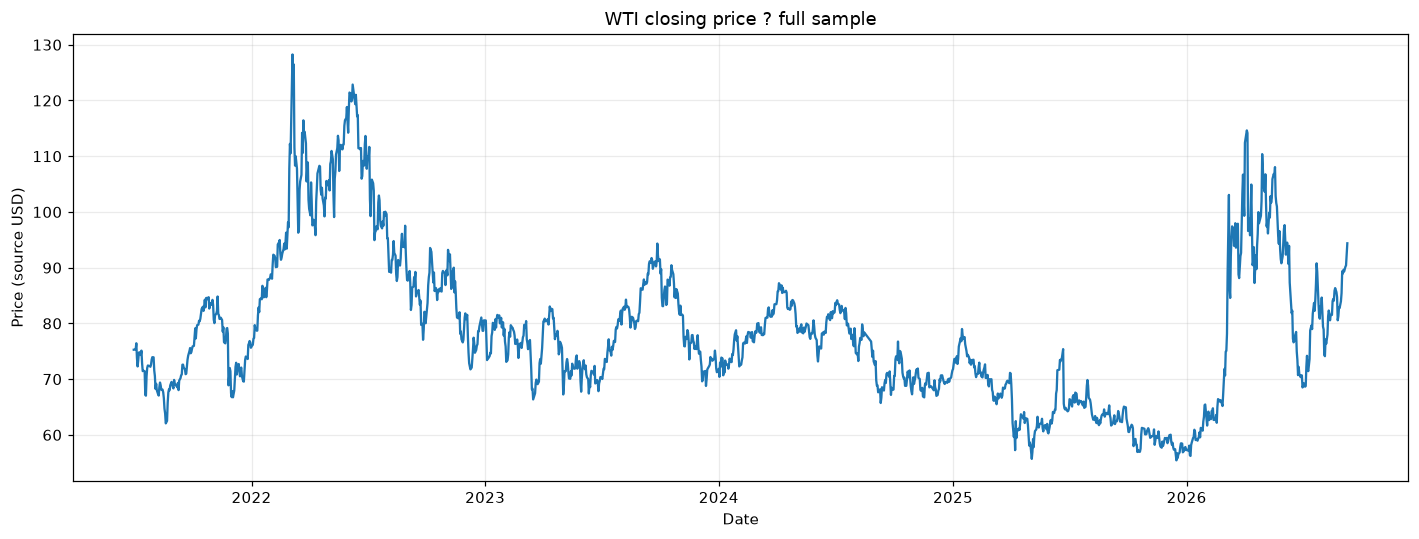

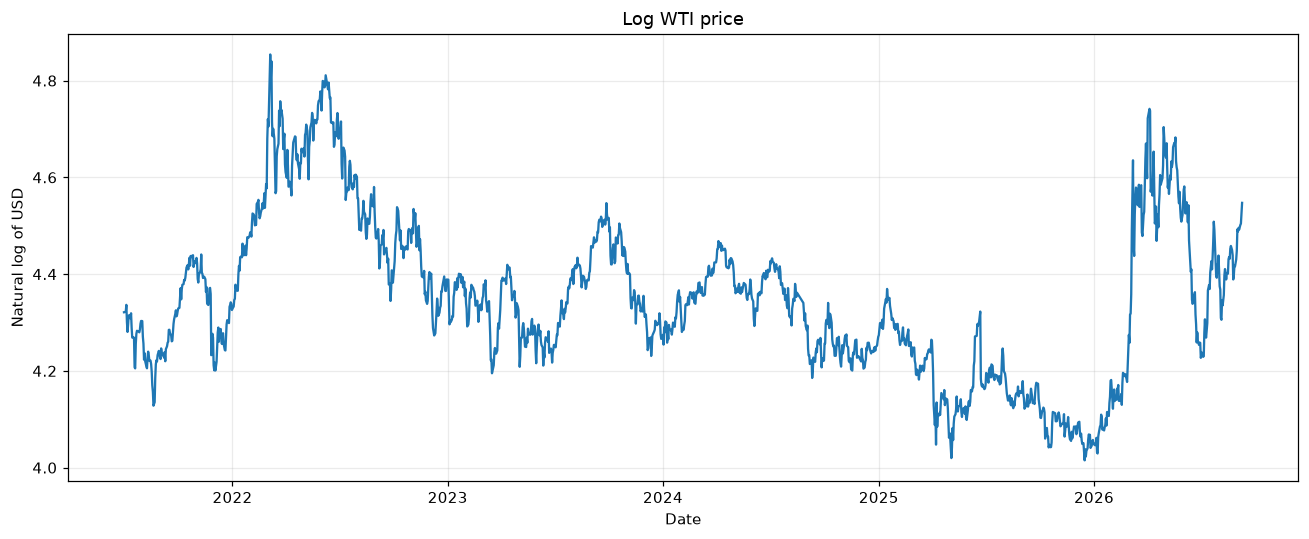

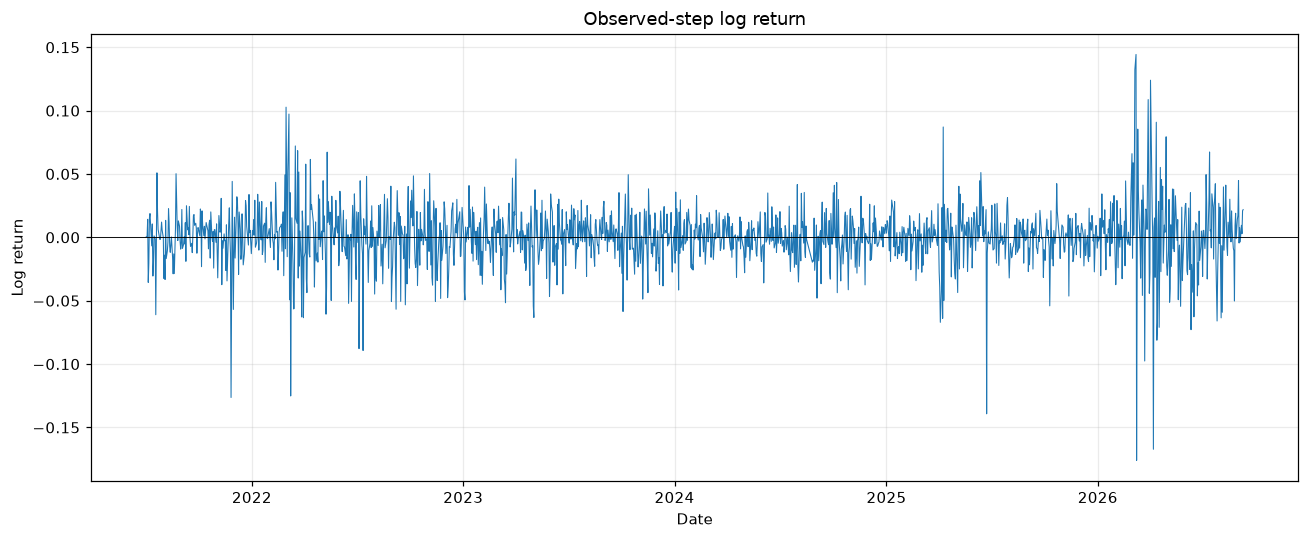

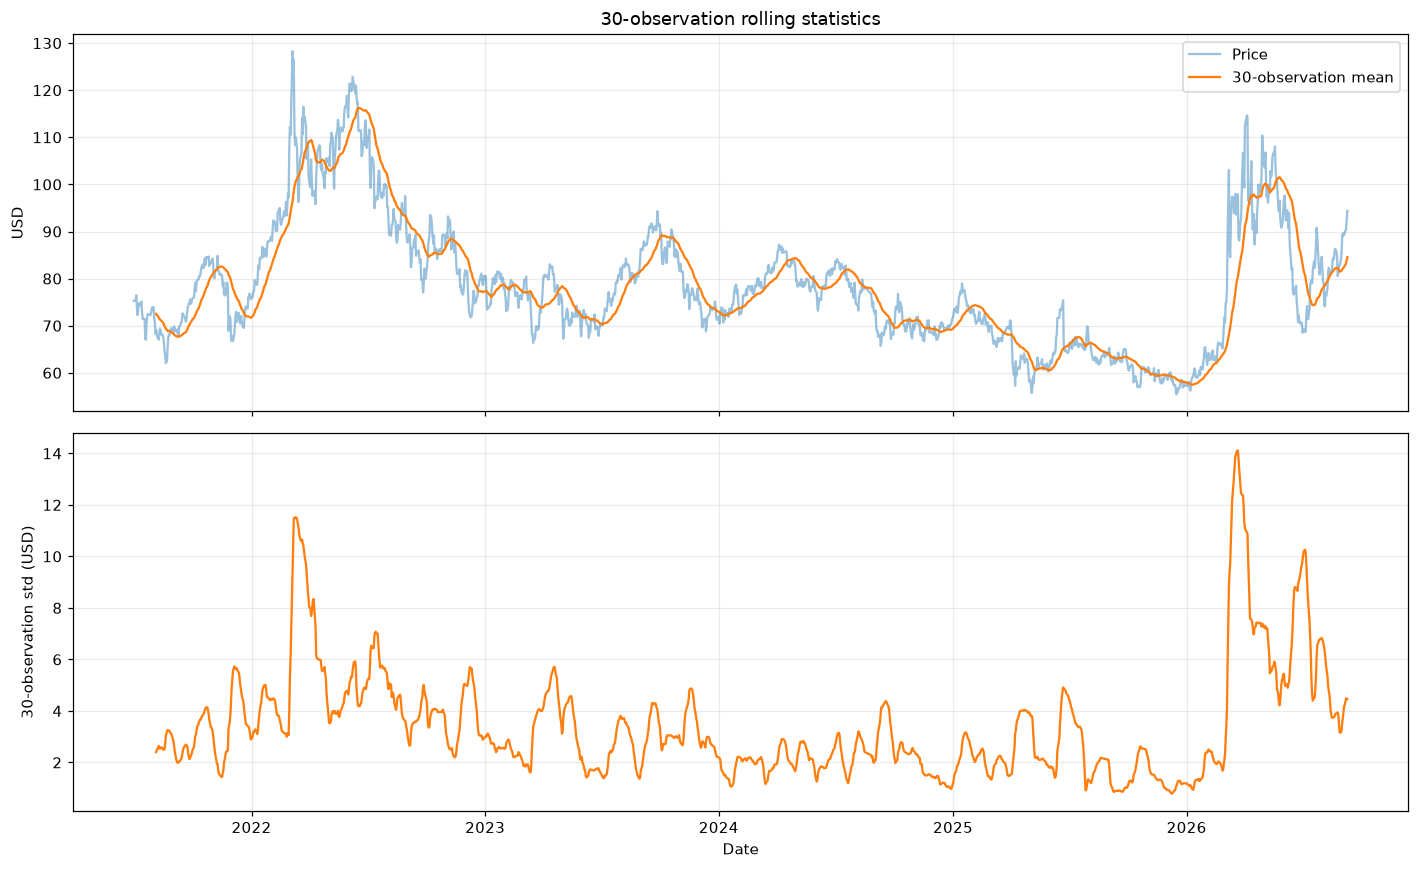

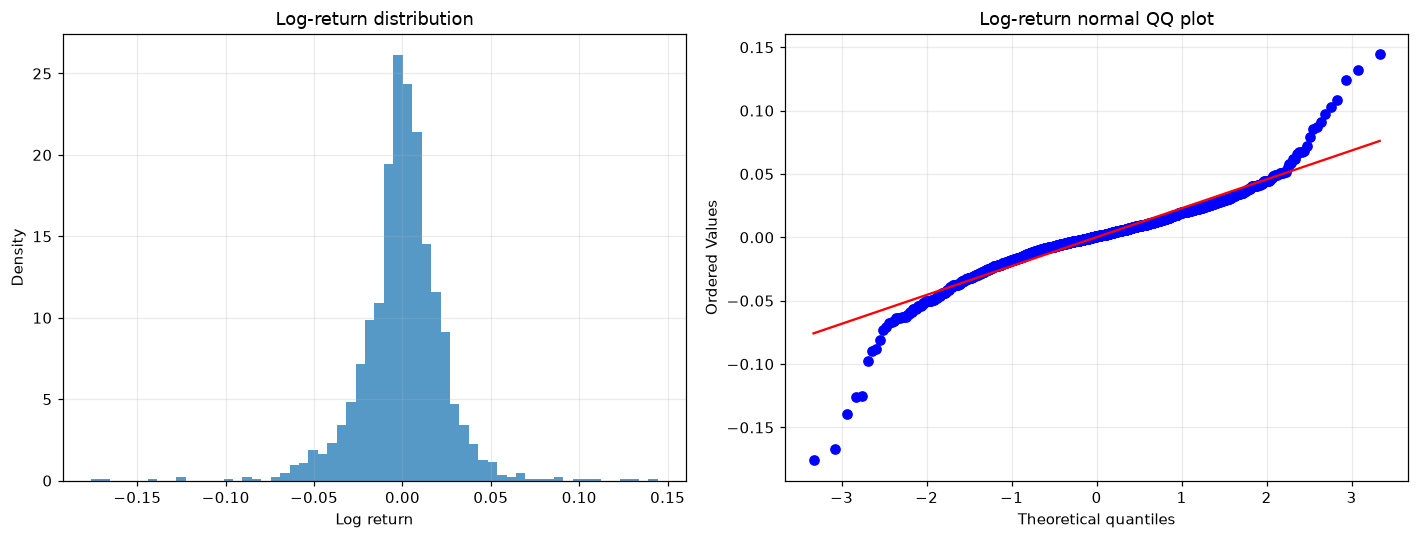

In [3]:
# First figure: raw WTI price over the full sample.
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df.index, df['Price'], color='tab:blue')
ax.set(title='WTI closing price ? full sample', ylabel='Price (source USD)', xlabel='Date')
save_figure(fig, '01_raw_price_volume.png')

fig, ax = plt.subplots()
ax.plot(log_price)
ax.set(title='Log WTI price', ylabel='Natural log of USD', xlabel='Date')
save_figure(fig, '02_log_price.png')

log_return = log_price.diff().dropna()
fig, ax = plt.subplots()
ax.plot(log_return, linewidth=0.7)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(title='Observed-step log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '03_log_return.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['Price'], alpha=0.45, label='Price')
axes[0].plot(df['Price'].rolling(30).mean(), label='30-observation mean')
axes[0].set(ylabel='USD', title='30-observation rolling statistics'); axes[0].legend()
axes[1].plot(df['Price'].rolling(30).std(), color='tab:orange')
axes[1].set(ylabel='30-observation std (USD)', xlabel='Date')
save_figure(fig, '04_rolling_stats.png')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_return, bins=60, density=True, alpha=0.75)
axes[0].set(title='Log-return distribution', xlabel='Log return', ylabel='Density')
stats.probplot(log_return, dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '05_return_distribution.png')


### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'USD (source price)'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,USD (source price),USD (source price),USD (source price)
Start,2021-07-01,2021-07-01,2025-08-28
End,2026-09-09,2025-08-27,2026-09-09
Count,1601,1280,321
Mean,78.479038,79.316008,75.141589
SD,13.413534,12.482122,16.214575
Min,55.43,55.69,55.43
Q1,69.34,70.8325,60.54
Median,76.61,77.085,69.26
Q3,84.67,84.1025,89.74


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-08-28
End,2026-09-09,2025-08-27,2026-09-09
Count,1600,1279,321
Mean,0.000141,-0.000132,0.00123
SD,0.023796,0.021209,0.032118
Min,-0.175977,-0.139251,-0.175977
Q1,-0.010166,-0.009932,-0.010752
Median,0.000871,0.000624,0.001594
Q3,0.01184,0.011387,0.014347


## Step 3 — Chronological Train/Test Split


,split,start_date,end_date,n_observations,min,max,mean
0,Train,2021-07-01,2025-08-27,1280,55.69,128.26,79.316008
1,Test,2025-08-28,2026-09-09,321,55.43,114.63,75.141589


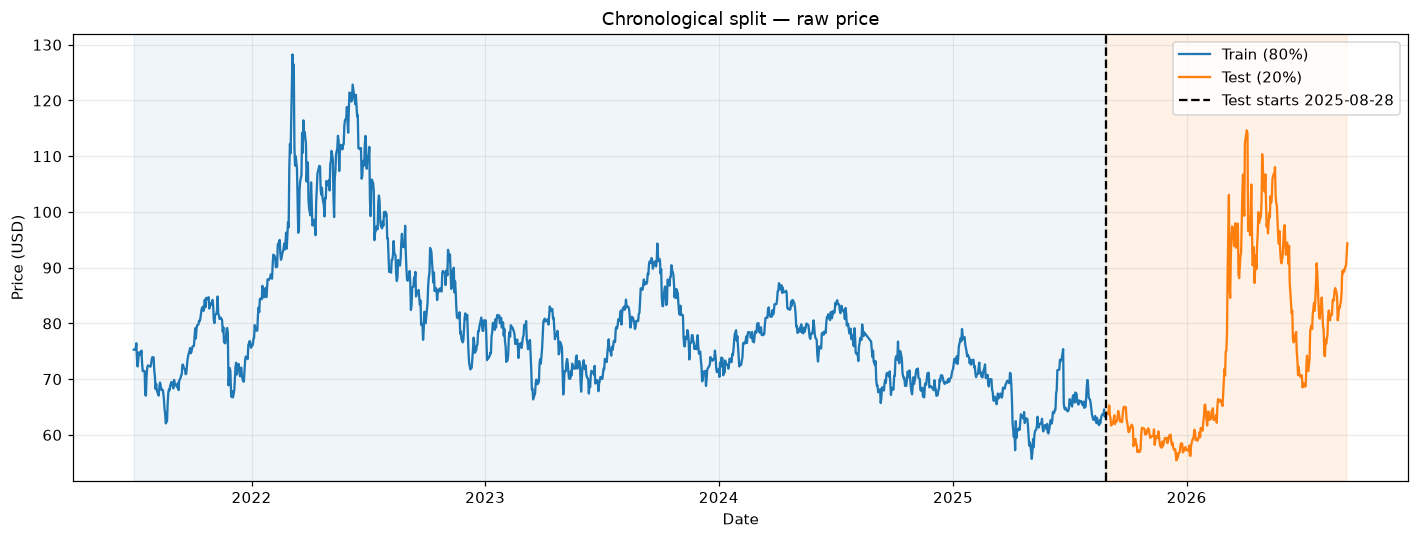

In [4]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
train_price = df['Price'].iloc[:n_train].copy()
test_price = df['Price'].iloc[n_train:].copy()
train_log = log_price.iloc[:n_train].copy()
assert n_train+n_test == n and n_test >= max(HORIZONS)
assert train_log.index[-1] < test_price.index[0]
train_model_log = model_history(train_log)
split_summary = pd.DataFrame([dict(split=name, start_date=x.index[0].date(),
    end_date=x.index[-1].date(), n_observations=len(x), min=x.min(), max=x.max(), mean=x.mean())
    for name, x in [('Train', train_price), ('Test', test_price)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_price, label='Train (80%)', color='tab:blue')
ax.plot(test_price, label='Test (20%)', color='tab:orange')
ax.axvspan(df.index[0], test_price.index[0], color='tab:blue', alpha=0.07)
ax.axvspan(test_price.index[0], df.index[-1], color='tab:orange', alpha=0.10)
ax.axvline(test_price.index[0], color='black', linestyle='--', label=f'Test starts {test_price.index[0].date()}')
ax.set(title='Chronological split — raw price', ylabel='Price (USD)', xlabel='Date')
ax.legend()
save_figure(fig, '06_train_test_split.png')


## Step 4 — Stationarity (Train Only)

As in BTC, verify nonstationary log levels and stationary first differences jointly with ADF/KPSS before using d=1. Do not substitute another d based on Test.

In [5]:
train_diff = train_log.diff().dropna()
stationarity_rows = []
for series_name, values in [('log_price', train_log), ('diff_log_price', train_diff)]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf = adfuller(values, autolag='AIC')
    stationarity_rows.append(dict(series=series_name, test='ADF', statistic=adf[0],
        p_value=adf[1], critical_values=json.dumps(adf[4]),
        conclusion='stationary' if adf[1] < ALPHA else 'non-stationary (fail to reject H0)',
        stationary=adf[1] < ALPHA, warnings=warning_text(caught)))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        kp = kpss(values, regression='c', nlags='auto')
    stationarity_rows.append(dict(series=series_name, test='KPSS', statistic=kp[0],
        p_value=kp[1], critical_values=json.dumps(kp[3]),
        conclusion='stationary (fail to reject H0)' if kp[1] > ALPHA else 'non-stationary',
        stationary=kp[1] > ALPHA, warnings=warning_text(caught)))
stationarity_tests = pd.DataFrame(stationarity_rows)
save_table(stationarity_tests, 'stationarity_tests.csv')
display(stationarity_tests)
level_stationary = stationarity_tests.loc[stationarity_tests['series'].eq('log_price'), 'stationary'].all()
diff_stationary = stationarity_tests.loc[stationarity_tests['series'].eq('diff_log_price'), 'stationary'].all()
assert not level_stationary and diff_stationary, 'Train ADF/KPSS do not jointly support the specified d=1.'
d = 1
print('Train stationarity evidence supports d =', d)


,series,test,statistic,p_value,critical_values,conclusion,stationary,warnings
0,log_price,ADF,-1.952253,3.078925e-01,"{""1%"": -3.4355013723543166, ""5%"": -2.863814884...",non-stationary (fail to reject H0),False,adfuller currently returns a plain tuple whose...
1,log_price,KPSS,2.176994,1.000000e-02,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",non-stationary,False,The test statistic is outside of the range of ...
2,diff_log_price,ADF,-14.153659,2.140171e-26,"{""1%"": -3.435509501237317, ""5%"": -2.8638184714...",stationary,True,adfuller currently returns a plain tuple whose...
3,diff_log_price,KPSS,0.058097,1.000000e-01,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",stationary (fail to reject H0),True,The test statistic is outside of the range of ...


Train stationarity evidence supports d = 1


## Step 5 — Model Identification (Train Only)

BTC grid: p,q=0..5, d=1, no-drift/drift. Rank converged finite-AIC fits by AIC/BIC/model and retain Top 3. auto_arima is a supplementary Train-only cross-check, not a replacement selection rule.

**AIC Rank:** อันดับเริ่มจาก 1 เฉพาะโมเดลที่ converged, AIC finite และไม่มี fit error เรียง AIC จากน้อยไปมาก แล้วใช้ BIC และชื่อโมเดลเมื่อค่าเท่ากัน ตารางด้านล่างแสดง **Top 5** เพื่อเปรียบเทียบ โดยยังใช้ **Top 3** สำหรับการเลือกโมเดลใน Step 6 ตามกติกาเดิมของ notebook นี้ ไม่เปลี่ยนผลพยากรณ์


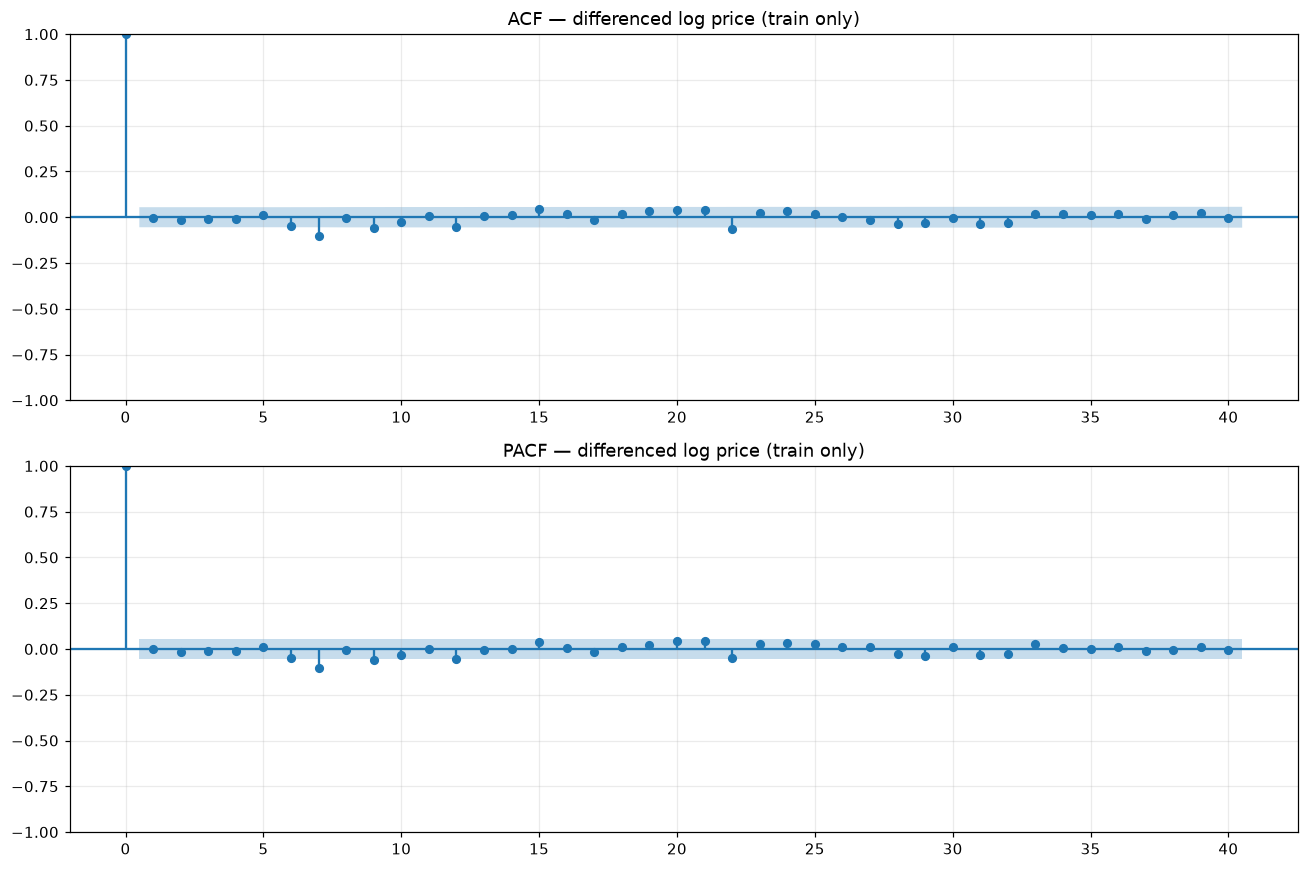

Grid progress: p=0, 12/72 fits completed


Grid progress: p=1, 24/72 fits completed


Grid progress: p=2, 36/72 fits completed


Grid progress: p=3, 48/72 fits completed


Grid progress: p=4, 60/72 fits completed


Grid progress: p=5, 72/72 fits completed


AIC Rank,model,p,d,q,trend,AIC,BIC,converged,warnings,error
1,"ARIMA(1,1,1), trend=n",1,1,1,n,-6227.463006,-6212.001505,True,,
2,"ARIMA(2,1,1), trend=n",2,1,1,n,-6226.490019,-6205.874684,True,,
3,"ARIMA(0,1,0), trend=n",0,1,0,n,-6226.091856,-6220.938022,True,,
4,"ARIMA(1,1,1), trend=t",1,1,1,t,-6225.545789,-6204.930453,True,,
5,"ARIMA(0,1,0), trend=t",0,1,0,t,-6224.141224,-6213.833556,True,,


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(train_diff, lags=40, ax=axes[0])
plot_pacf(train_diff, lags=40, method='ywm', ax=axes[1])
axes[0].set_title('ACF — differenced log price (train only)')
axes[1].set_title('PACF — differenced log price (train only)')
save_figure(fig, '07_acf_pacf.png')

grid_rows, fitted_models = [], {}
for p in range(MAX_P + 1):
    for q in range(MAX_Q + 1):
        for trend in ['n', 't']:
            label = f'ARIMA({p},{d},{q}), trend={trend}'
            row = dict(model=label, p=p, d=d, q=q, trend=trend, AIC=np.nan,
                       BIC=np.nan, converged=False, warnings='', error='')
            caught = []
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    result = ARIMA(train_model_log, order=(p, d, q), trend=trend).fit()
                row.update(AIC=result.aic, BIC=result.bic,
                           converged=bool(result.mle_retvals.get('converged', False)))
                fitted_models[label] = result
            except Exception as exc:
                row['error'] = f'{type(exc).__name__}: {exc}'
            row['warnings'] = warning_text(caught)
            grid_rows.append(row)
    print(f'Grid progress: p={p}, {len(grid_rows)}/72 fits completed', flush=True)
grid_search = pd.DataFrame(grid_rows).sort_values(['AIC', 'BIC', 'model'], na_position='last').reset_index(drop=True)
# Sequential AIC ranks among converged, finite-AIC, error-free Train fits.
eligible_mask = grid_search['converged'] & np.isfinite(grid_search['AIC']) & grid_search['error'].eq('')
grid_search.insert(0, 'AIC Rank', pd.Series(pd.NA, index=grid_search.index, dtype='Int64'))
grid_search.loc[eligible_mask, 'AIC Rank'] = np.arange(1, int(eligible_mask.sum()) + 1)
save_table(grid_search, 'grid_search_aic_bic.csv')
eligible = grid_search.loc[eligible_mask].copy()
assert len(eligible) >= 3, 'Fewer than three converged grid candidates; inspect grid_search_aic_bic.csv'
candidates = eligible.head(3).copy()
save_table(candidates, 'top3_candidates.csv')
# Show Top 5 for comparison; the original Top 3 selection is unchanged.
aic_rank_preview = eligible.head(5).copy()
display(aic_rank_preview.style.format({'AIC': '{:.6f}', 'BIC': '{:.6f}'}).hide(axis='index'))


In [7]:
cross_rows = []
for intercept in [False, True]:
    caught = []
    row = dict(with_intercept=intercept, order='', AIC=np.nan, BIC=np.nan,
               converged=False, warnings='', error='')
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            cross = pm.auto_arima(train_model_log, d=1, seasonal=False, stepwise=False,
                information_criterion='aic', start_p=0, start_q=0,
                max_p=MAX_P, max_q=MAX_Q, max_order=None, with_intercept=intercept,
                suppress_warnings=False, error_action='warn', n_jobs=1)
        row.update(order=str(cross.order), AIC=cross.aic(), BIC=cross.bic(),
                   converged=bool(cross.arima_res_.mle_retvals.get('converged', False)))
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    row['warnings'] = warning_text(caught)
    cross_rows.append(row)
    print(f'auto_arima cross-check complete: with_intercept={intercept}', flush=True)
cross_check = pd.DataFrame(cross_rows)
save_table(cross_check, 'auto_arima_cross_check.csv')
display(cross_check)
assert cross_check['error'].eq('').all(), 'auto_arima cross-check failed; inspect saved errors'


auto_arima cross-check complete: with_intercept=False


auto_arima cross-check complete: with_intercept=True


,with_intercept,order,AIC,BIC,converged,warnings,error
0,False,"(1, 1, 1)",-6227.463006,-6212.001505,True,Non-stationary starting autoregressive paramet...,
1,True,"(0, 1, 0)",-6224.141438,-6213.833770,True,Non-stationary starting autoregressive paramet...,


## Step 6 — Residual Diagnostics & Final Model (Train Only)

Keep BTC's Top 3 AIC shortlist, root checks, Ljung-Box alpha=0.05 at lags 10/20/30, and robust reporting. Prefer the lowest-AIC shortlisted fit passing both Ljung-Box and roots. As explicitly authorized for WTI, if none passes both, forecast with the lowest-AIC converged shortlisted fit whose roots pass and label it **FORECAST WITH RESIDUAL WARNING**. Failed Ljung-Box tests remain FAIL. Do not select a model with failed roots, adjust the diagnostic threshold, or use Test scores to decide this fallback.

Mean, ARCH, normality and significance remain reporting-only. Robust covariance reporting never replaces the original forecast parameters. Residual autocorrelation indicates remaining unexplained structure; the fallback supplies forecasts without claiming full statistical adequacy. Prediction intervals are model-based and may be miscalibrated.


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


model,AIC,BIC,ljung_box_pass,roots_pass,arch_pvalue,lb_pvalue_10,lb_pvalue_20,lb_pvalue_30
"ARIMA(1,1,1), trend=n",-6227.463006,-6212.001505,False,True,0.000000,0.033695,0.037757,0.036465
"ARIMA(2,1,1), trend=n",-6226.490019,-6205.874684,False,True,0.000000,0.028500,0.041440,0.040391
"ARIMA(0,1,0), trend=n",-6226.091856,-6220.938022,False,True,0.000000,0.013760,0.027846,0.026110


model,test,statistic,p_value,pass_fail,note
"ARIMA(1,1,1), trend=n",Ljung-Box lag 10,16.673420,0.033695,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Ljung-Box lag 20,29.968163,0.037757,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Ljung-Box lag 30,42.790134,0.036465,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Mean = 0 (t-test),-0.302149,0.762588,PASS,Residual mean=-0.00017881
"ARIMA(1,1,1), trend=n",ARCH LM (10 lags),97.822172,0.000000,FAIL,
"ARIMA(1,1,1), trend=n",Jarque-Bera,1178.301223,0.000000,FAIL,"skew=-0.5627, kurtosis=7.5655"
"ARIMA(1,1,1), trend=n",AR roots outside unit circle,1.122967,NaN,PASS,All |root|>1: True
"ARIMA(1,1,1), trend=n",MA roots outside unit circle,1.086956,NaN,PASS,All |root|>1: True
"ARIMA(1,1,1), trend=n",Parameter significance: ar.L1,0.890498,0.000000,PASS,"Report only; estimate in statistic column, significance uses p < alpha"
"ARIMA(1,1,1), trend=n",Parameter significance: ma.L1,-0.920001,0.000000,PASS,"Report only; estimate in statistic column, significance uses p < alpha"


**FORECAST WITH RESIDUAL WARNING**: no Top 3 fit passed all Ljung-Box checks. The lowest-AIC converged fit with valid roots is used under the user-authorized fallback. Ljung-Box failures remain FAIL; remaining autocorrelation and interval calibration limits are disclosed.

Selected: ARIMA(1,1,1), trend=n ; selection mode: ROOT_VALID_AIC_FALLBACK


,model,parameter,estimate,standard_error,p_value,significant,covariance
0,"ARIMA(1,1,1), trend=n",ar.L1,0.890498,0.067940,2.999885e-39,True,opg
1,"ARIMA(1,1,1), trend=n",ma.L1,-0.920001,0.059026,9.015470e-55,True,opg
2,"ARIMA(1,1,1), trend=n",sigma2,0.000447,0.000010,0.000000e+00,True,opg


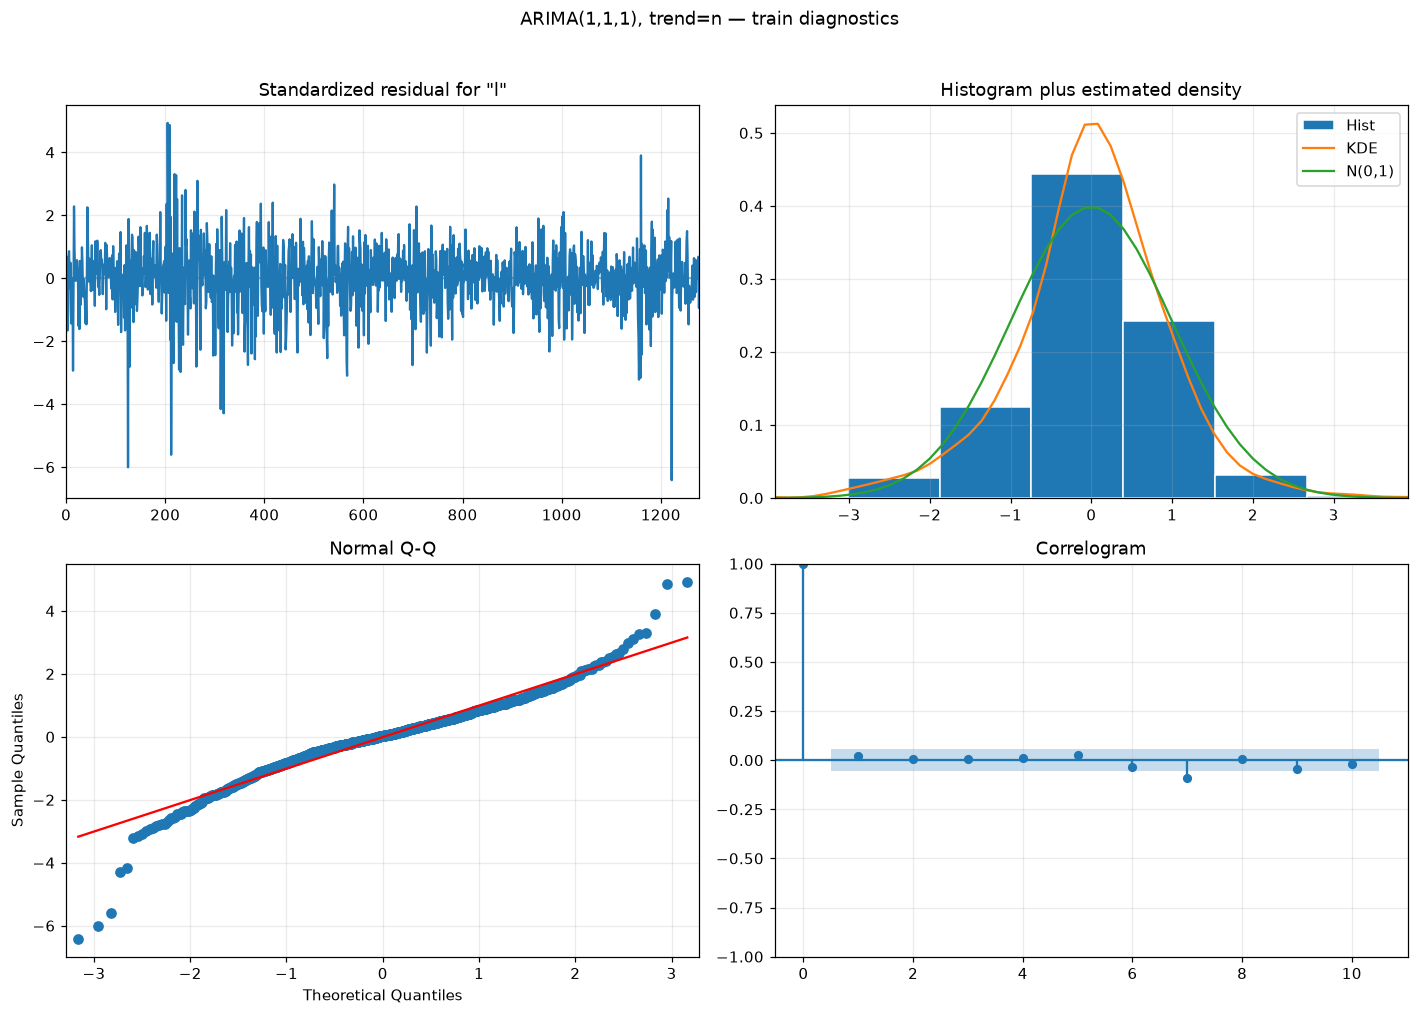

,model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
0,"ARIMA(1,1,1), trend=n",ar.L1,0.890498,0.090244,5.747221e-23,True,
1,"ARIMA(1,1,1), trend=n",ma.L1,-0.920001,0.076663,3.528969e-33,True,
2,"ARIMA(1,1,1), trend=n",sigma2,0.000447,0.000032,4.129550e-44,True,


Selection mode: ROOT_VALID_AIC_FALLBACK; diagnostic status: RESIDUAL_AUTOCORRELATION_WARNING

                               SARIMAX Results                                
Dep. Variable:              log_price   No. Observations:                 1280
Model:                 ARIMA(1, 1, 1)   Log Likelihood                3116.732
Date:                Tue, 27 Oct 2026   AIC                          -6227.463
Time:                        11:44:36   BIC                          -6212.002
Sample:                             0   HQIC                         -6221.657
                               - 1280                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8905      0.068     13.107      0.000       0.757       1.024
ma.L1         -0.9200      0.059    -

In [8]:
check_rows, parameter_rows, root_rows, candidate_status = [], [], [], []
robust_results, robust_rows, robust_warning_messages = {}, [], {}
def add_check(model, test, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    check_rows.append(dict(model=model, test=test, statistic=statistic, p_value=p_value,
                           pass_fail='REPORTED' if passed is None else ('PASS' if passed else 'FAIL'), note=note))

for item in candidates.itertuples(index=False):
    result = fitted_models[item.model]
    burn_in = max(d, int(result.loglikelihood_burn), int(getattr(result.filter_results,'nobs_diffuse',0)))
    residuals = pd.Series(np.asarray(result.resid)[burn_in:]).dropna()
    lb = acorr_ljungbox(residuals, lags=[10, 20, 30], model_df=item.p + item.q, return_df=True)
    lb_pass = bool(lb['lb_pvalue'].notna().all() and (lb['lb_pvalue'] > ALPHA).all())
    for lag, row in lb.iterrows():
        add_check(item.model, f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'],
                  bool(row['lb_pvalue'] > ALPHA), f'model_df={item.p + item.q}')
    mean_stat, mean_p = stats.ttest_1samp(residuals, 0)
    add_check(item.model, 'Mean = 0 (t-test)', mean_stat, mean_p, mean_p > ALPHA,
              f'Residual mean={residuals.mean():.6g}')
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=10)
    add_check(item.model, 'ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA)
    if arch_p <= ALPHA:
        with warnings.catch_warnings(record=True) as robust_caught:
            warnings.simplefilter('always')
            robust = ARIMA(train_model_log, order=(item.p, d, item.q), trend=item.trend).fit(cov_type='robust')
        robust_results[item.model] = robust
        robust_warning_messages[item.model] = warning_text(robust_caught)
        for name, coef, se, pv in zip(robust.param_names, robust.params, robust.bse, robust.pvalues):
            robust_rows.append(dict(model=item.model, parameter=name, estimate=coef,
                robust_standard_error=se, robust_p_value=pv,
                converged=bool(robust.mle_retvals.get('converged', False)),
                warnings=warning_text(robust_caught)))
    jb_stat, jb_p, skew, kurt = jarque_bera(residuals)
    add_check(item.model, 'Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
              f'skew={skew:.4f}, kurtosis={kurt:.4f}')
    roots_pass = True
    for kind, roots in [('AR', result.arroots), ('MA', result.maroots)]:
        moduli = np.abs(roots)
        passed = bool(np.isfinite(moduli).all() and (moduli > 1).all())
        roots_pass &= passed
        add_check(item.model, f'{kind} roots outside unit circle',
                  moduli.min() if len(moduli) else np.nan, passed=passed if len(moduli) else None,
                  note='N/A: no roots' if not len(moduli) else f'All |root|>1: {passed}')
        for j, root in enumerate(roots, 1):
            root_rows.append(dict(model=item.model, kind=kind, root_number=j,
                                  real=root.real, imag=root.imag, modulus=abs(root), outside=abs(root) > 1))
    for name, coef, se, pv in zip(result.param_names, result.params, result.bse, result.pvalues):
        parameter_rows.append(dict(model=item.model, parameter=name, estimate=coef, standard_error=se,
                                   p_value=pv, significant=pv < ALPHA, covariance=result.cov_type))
        add_check(item.model, f'Parameter significance: {name}', coef, pv, pv < ALPHA,
                  'Report only; estimate in statistic column, significance uses p < alpha')
    candidate_status.append(dict(model=item.model, AIC=item.AIC, BIC=item.BIC, ljung_box_pass=lb_pass,
        roots_pass=roots_pass, arch_pvalue=arch_p,
        **{f'lb_pvalue_{lag}':float(lb.loc[lag,'lb_pvalue']) for lag in LB_LAGS}))

assumption_checks = pd.DataFrame(check_rows)
parameter_significance = pd.DataFrame(parameter_rows)
candidate_diagnostics = pd.DataFrame(candidate_status).sort_values('AIC')
save_table(assumption_checks, 'assumption_checks.csv')
save_table(parameter_significance, 'parameter_significance.csv')
save_table(pd.DataFrame(root_rows, columns=['model','kind','root_number','real','imag','modulus','outside']), 'model_roots.csv')
save_table(candidate_diagnostics, 'candidate_diagnostics.csv')
if robust_rows:
    save_table(pd.DataFrame(robust_rows), 'robust_parameter_significance.csv')
show_table(candidate_diagnostics)
show_table(assumption_checks)
strict_passing = candidate_diagnostics.loc[candidate_diagnostics['ljung_box_pass'] & candidate_diagnostics['roots_pass']]
if not strict_passing.empty:
    passing = strict_passing.copy()
    selection_mode = 'STRICT_DIAGNOSTICS'
    train_diagnostics_passed = True
    diagnostic_status = 'TRAIN_LJUNG_BOX_AND_ROOTS_PASS'
else:
    # User-authorized WTI fallback; do not relabel any failed diagnostic as PASS.
    passing = candidate_diagnostics.loc[candidate_diagnostics['roots_pass']].copy()
    selection_mode = 'ROOT_VALID_AIC_FALLBACK' if not passing.empty else 'NO_VALID_MODEL'
    train_diagnostics_passed = False
    diagnostic_status = 'RESIDUAL_AUTOCORRELATION_WARNING' if not passing.empty else 'NO_VALID_MODEL'
accepted_model = not passing.empty
candidate_diagnostics['selected'] = False
if accepted_model:
    candidate_diagnostics.loc[candidate_diagnostics.model.eq(passing.iloc[0]['model']), 'selected'] = True
candidate_diagnostics['selection_mode'] = selection_mode
save_table(candidate_diagnostics, 'candidate_diagnostics.csv')
if accepted_model and not train_diagnostics_passed:
    display(Markdown('**FORECAST WITH RESIDUAL WARNING**: no Top 3 fit passed all Ljung-Box checks. '
        'The lowest-AIC converged fit with valid roots is used under the user-authorized fallback. '
        'Ljung-Box failures remain FAIL; remaining autocorrelation and interval calibration limits are disclosed.'))
if accepted_model:
    final_label = passing.iloc[0]['model']
    final_spec = candidates.set_index('model').loc[final_label]
    res = fitted_models[final_label]  # reuse original train fit; frozen forecast parameters
    frozen_params = np.asarray(res.params).copy()
    assert res.nobs == n_train
    print('Selected:', final_label, '; selection mode:', selection_mode)
    display(parameter_significance.loc[parameter_significance['model'].eq(final_label)])
    fig = res.plot_diagnostics(figsize=(13, 9))
    fig.suptitle(f'{final_label} — train diagnostics', y=1.02)
    save_figure(fig, '08_residual_diagnostics.png')
    
    summary_text = f'Selection mode: {selection_mode}; diagnostic status: {diagnostic_status}\n\n' + res.summary().as_text()
    robust_res = None
    if passing.iloc[0]['arch_pvalue'] <= ALPHA:
        robust_res = robust_results[final_label]
        display(pd.DataFrame(robust_rows).loc[lambda x: x['model'].eq(final_label)])
        summary_text += '\n\nROBUST COVARIANCE REFIT ON TRAIN — reporting only; forecasts retain original parameters.\n'
        summary_text += robust_res.summary().as_text()
        summary_text += '\nWarnings: ' + robust_warning_messages[final_label]
        summary_text += '\nRobust refit converged: ' + str(robust_res.mle_retvals.get('converged', False))
    assert np.array_equal(np.asarray(res.params), frozen_params)
    (SUMMARY_DIR / 'final_model_summary.txt').write_text(summary_text, encoding='utf-8')
    print(summary_text)
    
    accepted_model = True
    res.save(MODEL_DIR/'arima_train.pkl')
    write_json(MODEL_DIR/'selected_order.json', dict(order=[int(final_spec.p),d,int(final_spec.q)], trend=final_spec.trend,
        parameters=frozen_params.tolist(), fit_end_date=train_log.index[-1], fit_n=n_train,
        selection=configuration['selection'], selection_mode=selection_mode,
        train_diagnostics_passed=train_diagnostics_passed, diagnostic_status=diagnostic_status))
else:

    stop_message = 'No converged Top 3 candidate has valid roots. The authorized residual-warning fallback cannot select a model.'
    display(Markdown('**Selection status: NO ACCEPTED MODEL**\n\n'+stop_message+
        '\n\nSteps 7-8 will show a skipped status; Step 9 will summarize the actual diagnostic evidence. No forecasts or metrics are fabricated.'))
    write_json(SUMMARY_DIR/'execution_audit.json', dict(completed=False, status='NO_ACCEPTED_MODEL',
        asset=ASSET, model_accepted=False, forecasts_generated=False, stopped_selection_step=6,
        reason=stop_message, candidate_diagnostics=candidate_diagnostics.to_dict('records'),
        note='Prior model/forecast exports are not current results.'))


## Step 7 - Forecast Values by Horizon
The next cells produce forecasts using the parameters estimated on train.
`arima_fc` is the point forecast in USD; `arima_lo95` and `arima_hi95` are its model-based 95% prediction-interval bounds.
The exp-transformed log forecast mean is a conditional median on the USD scale.

### 7.1 Rolling-origin forecasts for the test period
Each origin uses observations up to that date only, with `refit=False`.

In [9]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    log_all = log_price
    forecast_rows = []
    for i in range(n_train - 1, n - 1):
        r = res.apply(model_history(log_all.iloc[:i+1]), refit=False)
        assert np.array_equal(np.asarray(r.params), frozen_params), 'Parameters changed during test'
        fc = r.get_forecast(steps=max(HORIZONS))
        means = np.asarray(fc.predicted_mean)
        ci = np.asarray(fc.conf_int(alpha=ALPHA))
        for h in HORIZONS:
            target = i + h
            if target < n:
                row = dict(origin_date=log_all.index[i], h=h, target_date=log_all.index[target],
                    actual=df['Price'].iloc[target], arima_fc=np.exp(means[h-1]),
                    arima_lo95=np.exp(ci[h-1, 0]), arima_hi95=np.exp(ci[h-1, 1]),
                    price_origin=df['Price'].iloc[i])
                # Treat rounding noise as zero price movement, not a predicted direction.
                if np.isclose(row['arima_fc'], row['price_origin'], rtol=32*np.finfo(float).eps, atol=0):
                    row['arima_fc'] = row['price_origin']
                forecast_rows.append(row)
        if (i - n_train + 2) % 50 == 0:
            print(f'Rolling origins completed: {i - n_train + 2}/{n_test}', flush=True)
    forecasts = pd.DataFrame(forecast_rows).sort_values(['h', 'target_date']).reset_index(drop=True)
    counts = forecasts.groupby('h').size()
    for h in HORIZONS:
        assert counts[h] == n_test - h + 1, (h, counts[h])
    assert (forecasts['target_date'] >= test_price.index[0]).all()
    assert (df.index.get_indexer(forecasts.target_date)-df.index.get_indexer(forecasts.origin_date) == forecasts.h.to_numpy()).all()
    assert not forecasts.duplicated(['origin_date', 'h']).any()
    assert np.isfinite(forecasts.select_dtypes('number').to_numpy()).all()
    assert (forecasts['arima_lo95'] <= forecasts['arima_hi95']).all()
    forecasts['diagnostic_status'] = diagnostic_status
    save_table(forecasts, 'forecasts_long.csv')
    display(counts.rename('n_points').to_frame())
    
    assert (forecasts[['actual','arima_fc','arima_lo95','arima_hi95']] > 0).all().all()
    assert (forecasts.arima_lo95 <= forecasts.arima_fc).all() and (forecasts.arima_fc <= forecasts.arima_hi95).all()


Rolling origins completed: 50/321


Rolling origins completed: 100/321


Rolling origins completed: 150/321


Rolling origins completed: 200/321


Rolling origins completed: 250/321


Rolling origins completed: 300/321


,n_points
h,
1,321
3,319
5,317
7,315
14,308
21,301
30,292


### 7.2 Test forecast tables - h = 1, 3, 5, 7, 14, 21, 30
Each table displays every forecast at that horizon: origin date, target date, price at origin, actual target price, and forecast in USD.
Scroll inside a table to inspect all dates. Full tables are also exported to `OUTPUT/ARIMA_BTC/tables/forecasts_h{h}.csv`.

In [10]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    # All test forecasts are visible in scrollable tables; export all rows per horizon.
    forecast_columns = ['origin_date', 'target_date', 'price_origin', 'actual',
                        'arima_fc', 'arima_lo95', 'arima_hi95', 'diagnostic_status']
    for h in HORIZONS:
        horizon_forecasts = forecasts.loc[forecasts['h'].eq(h), forecast_columns].copy()
        save_table(horizon_forecasts, f'forecasts_h{h}.csv')
        display(Markdown(f'**Test forecasts: h = {h} observations ({len(horizon_forecasts)} rows)**'))
        table_html = horizon_forecasts.to_html(index=False, float_format=lambda x: f'{x:,.2f}')
        display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
                     + table_html + '</div>'))


**Test forecasts: h = 1 observations (321 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2025-08-27,2025-08-28,63.60,63.96,63.61,61.02,66.30,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-28,2025-08-29,63.96,63.79,63.95,61.36,66.66,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-29,2025-08-31,63.79,63.72,63.79,61.20,66.49,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-31,2025-09-01,63.72,64.36,63.72,61.13,66.42,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-01,2025-09-02,64.36,65.29,64.34,61.73,67.07,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-02,2025-09-03,65.29,63.55,65.25,62.60,68.01,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-03,2025-09-04,63.55,63.02,63.56,60.98,66.25,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-04,2025-09-05,63.02,61.67,63.05,60.49,65.71,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-05,2025-09-07,61.67,61.96,61.73,59.23,64.35,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-07,2025-09-08,61.96,62.17,62.01,59.49,64.63,RESIDUAL_AUTOCORRELATION_WARNING


**Test forecasts: h = 3 observations (319 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2025-08-27,2025-08-31,63.60,63.72,63.62,59.33,68.21,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-28,2025-09-01,63.96,64.36,63.95,59.64,68.57,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-29,2025-09-02,63.79,65.29,63.79,59.49,68.40,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-31,2025-09-03,63.72,63.55,63.73,59.43,68.33,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-01,2025-09-04,64.36,63.02,64.31,59.98,68.96,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-02,2025-09-05,65.29,61.67,65.17,60.78,69.88,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-03,2025-09-07,63.55,61.96,63.58,59.30,68.18,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-04,2025-09-08,63.02,62.17,63.09,58.84,67.65,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-05,2025-09-09,61.67,62.79,61.84,57.67,66.31,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-07,2025-09-10,61.96,63.51,62.09,57.91,66.58,RESIDUAL_AUTOCORRELATION_WARNING


**Test forecasts: h = 5 observations (317 rows)**

...

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2025-08-27,2025-09-12,63.60,62.37,63.64,55.57,72.88,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-28,2025-09-14,63.96,62.44,63.92,55.82,73.20,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-29,2025-09-15,63.79,63.07,63.79,55.70,73.05,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-31,2025-09-16,63.72,64.28,63.74,55.66,72.99,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-01,2025-09-17,64.36,63.75,64.24,56.09,73.56,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-02,2025-09-18,65.29,63.19,64.97,56.74,74.41,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-03,2025-09-19,63.55,62.39,63.64,55.57,72.88,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-04,2025-09-21,63.02,62.48,63.21,55.20,72.39,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-05,2025-09-22,61.67,62.28,62.13,54.26,71.16,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-07,2025-09-23,61.96,63.62,62.33,54.42,71.38,RESIDUAL_AUTOCORRELATION_WARNING


**Test forecasts: h = 21 observations (301 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2025-08-27,2025-09-21,63.60,62.48,63.65,54.26,74.67,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-28,2025-09-22,63.96,62.28,63.92,54.48,74.98,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-29,2025-09-23,63.79,63.62,63.79,54.38,74.84,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-31,2025-09-24,63.72,64.57,63.74,54.33,74.77,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-01,2025-09-25,64.36,65.07,64.22,54.74,75.34,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-02,2025-09-26,65.29,65.00,64.93,55.35,76.17,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-03,2025-09-28,63.55,64.94,63.65,54.26,74.67,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-04,2025-09-29,63.02,62.92,63.24,53.91,74.19,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-05,2025-09-30,61.67,62.31,62.20,53.02,72.97,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-07,2025-10-01,61.96,61.65,62.38,53.17,73.18,RESIDUAL_AUTOCORRELATION_WARNING


**Test forecasts: h = 30 observations (292 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2025-08-27,2025-10-01,63.60,61.65,63.65,52.92,76.56,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-28,2025-10-02,63.96,60.54,63.91,53.14,76.88,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-29,2025-10-03,63.79,60.50,63.79,53.04,76.73,RESIDUAL_AUTOCORRELATION_WARNING
2025-08-31,2025-10-05,63.72,61.38,63.74,52.99,76.67,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-01,2025-10-06,64.36,61.47,64.21,53.38,77.24,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-02,2025-10-07,65.29,61.82,64.91,53.96,78.07,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-03,2025-10-08,63.55,61.67,63.66,52.92,76.57,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-04,2025-10-09,63.02,61.20,63.25,52.59,76.08,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-05,2025-10-10,61.67,57.98,62.23,51.74,74.85,RESIDUAL_AUTOCORRELATION_WARNING
2025-09-07,2025-10-12,61.96,59.21,62.40,51.88,75.06,RESIDUAL_AUTOCORRELATION_WARNING


### 7.3 Future forecasts from the latest observed date
This seven-row table uses a common origin: the final date in the CSV. Target dates are 1, 3, 5, 7, 14, 21 and 30 observations later.
Only filtering states are updated with the full observed history; model order and train-estimated parameters remain fixed.
These are future values, separate from the historical test forecasts evaluated below. No future actual prices are assumed.

In [11]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    # Update filtering states with the latest observed data, keeping train parameters fixed.
    latest_origin = log_all.index[-1]
    latest_result = res.apply(model_history(log_all), refit=False)
    assert np.array_equal(np.asarray(latest_result.params), frozen_params)
    latest_fc = latest_result.get_forecast(steps=max(max(HORIZONS), max(DAILY_FORECAST_WINDOWS)))
    latest_means = np.exp(np.asarray(latest_fc.predicted_mean))
    latest_ci = np.exp(np.asarray(latest_fc.conf_int(alpha=ALPHA)))
    latest_price = float(df['Price'].iloc[-1])
    future_dates = pd.date_range(latest_origin+calendar_offset, periods=max(max(HORIZONS),max(DAILY_FORECAST_WINDOWS)), freq=calendar_offset)
    future_rows = []
    for h in HORIZONS:
        value = latest_means[h-1]
        if np.isclose(value, latest_price, rtol=32*np.finfo(float).eps, atol=0):
            value = latest_price
        future_rows.append(dict(origin_date=latest_origin, h=h,
            target_date=future_dates[h-1], target_date_status='PROJECTED: source weekday pattern; sessions unknown',
            arima_fc=value, arima_lo95=latest_ci[h-1, 0], arima_hi95=latest_ci[h-1, 1]))
    future_forecasts = pd.DataFrame(future_rows)
    future_forecasts['diagnostic_status'] = diagnostic_status
    assert future_forecasts['h'].tolist() == HORIZONS
    assert (future_forecasts['target_date'] > df.index[-1]).all()
    save_table(future_forecasts, 'future_forecast_by_horizon.csv')
    print(f'Forecast origin: {latest_origin.date()}, last observed price: {latest_price:,.2f} USD')
    display(future_forecasts.style.format({'origin_date': lambda x: x.strftime('%Y-%m-%d'),
        'target_date': lambda x: x.strftime('%Y-%m-%d'),
        'arima_fc': '{:,.2f}', 'arima_lo95': '{:,.2f}', 'arima_hi95': '{:,.2f}'}).hide(axis='index'))


Forecast origin: 2026-09-09, last observed price: 94.38 USD


origin_date,h,target_date,target_date_status,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2026-09-09,1,2026-09-10,PROJECTED: source weekday pattern; sessions unknown,94.12,90.29,98.10,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,3,2026-09-13,PROJECTED: source weekday pattern; sessions unknown,93.67,87.36,100.44,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,5,2026-09-15,PROJECTED: source weekday pattern; sessions unknown,93.32,85.48,101.89,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,7,2026-09-17,PROJECTED: source weekday pattern; sessions unknown,93.05,84.05,103.01,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,14,2026-09-25,PROJECTED: source weekday pattern; sessions unknown,92.46,80.74,105.89,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,21,2026-10-04,PROJECTED: source weekday pattern; sessions unknown,92.21,78.60,108.17,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,30,2026-10-14,PROJECTED: source weekday pattern; sessions unknown,92.07,76.55,110.75,RESIDUAL_AUTOCORRELATION_WARNING


### 7.4 Daily future forecast tables  next 7 and 30 observations
 `OUTPUT/ARIMA_BTC/tables/future_forecast_observed-step_7d.csv`  `future_forecast_observed-step_30d.csv`.


In [12]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    # Reuse the same latest-origin forecast path; no model fitting or selection.
    daily_steps = max(DAILY_FORECAST_WINDOWS)
    daily_dates = future_dates[:daily_steps]
    daily_point = latest_means[:daily_steps].copy()
    daily_point[np.isclose(daily_point, latest_price, rtol=32*np.finfo(float).eps, atol=0)] = latest_price
    future_forecast_daily = pd.DataFrame({
        'origin_date': latest_origin,
        'h': np.arange(1, daily_steps + 1),
        'target_date': daily_dates,
        'day_of_week': daily_dates.day_name(),
        'price_origin': latest_price,
        'arima_fc': daily_point,
        'arima_lo95': latest_ci[:daily_steps, 0],
        'arima_hi95': latest_ci[:daily_steps, 1],
    })
    future_forecast_daily['diagnostic_status'] = diagnostic_status
    assert np.array_equal(np.asarray(latest_result.params), frozen_params)
    assert len(future_forecast_daily) == daily_steps
    assert (future_forecast_daily.target_date > latest_origin).all()
    assert future_forecast_daily.h.tolist() == list(range(1,daily_steps+1))
    assert not future_forecast_daily['target_date'].duplicated().any()
    assert np.isfinite(future_forecast_daily.select_dtypes('number').to_numpy()).all()
    assert (future_forecast_daily[['price_origin', 'arima_fc', 'arima_lo95', 'arima_hi95']] > 0).all().all()
    assert (future_forecast_daily['arima_lo95'] <= future_forecast_daily['arima_fc']).all()
    assert (future_forecast_daily['arima_fc'] <= future_forecast_daily['arima_hi95']).all()
    # Requested-horizon rows must agree with section 7.3.
    np.testing.assert_allclose(
        future_forecast_daily.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']],
        future_forecasts.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']],
        rtol=1e-12,
    )
    future_daily_tables = {}
    for days in DAILY_FORECAST_WINDOWS:
        table = future_forecast_daily.iloc[:days].copy()
        assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
        future_daily_tables[days] = table
        save_table(table, f'future_forecast_daily_{days}d.csv')
        display(Markdown(f'**Next {days} projected observations ? origin {latest_origin.date()}, last price {latest_price:,.2f} USD**'))
        shown = table.copy()
        for column in ['origin_date', 'target_date']:
            shown[column] = shown[column].dt.strftime('%Y-%m-%d')
        display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.2f}')))


**Next 7 projected observations ? origin 2026-09-09, last price 94.38 USD**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2026-09-09,1,2026-09-10,Thursday,94.38,94.12,90.29,98.10,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,2,2026-09-11,Friday,94.38,93.88,88.61,99.47,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,3,2026-09-13,Sunday,94.38,93.67,87.36,100.44,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,4,2026-09-14,Monday,94.38,93.49,86.34,101.23,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,5,2026-09-15,Tuesday,94.38,93.32,85.48,101.89,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,6,2026-09-16,Wednesday,94.38,93.18,84.72,102.48,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,7,2026-09-17,Thursday,94.38,93.05,84.05,103.01,RESIDUAL_AUTOCORRELATION_WARNING


**Next 30 projected observations ? origin 2026-09-09, last price 94.38 USD**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95,diagnostic_status
2026-09-09,1,2026-09-10,Thursday,94.38,94.12,90.29,98.10,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,2,2026-09-11,Friday,94.38,93.88,88.61,99.47,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,3,2026-09-13,Sunday,94.38,93.67,87.36,100.44,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,4,2026-09-14,Monday,94.38,93.49,86.34,101.23,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,5,2026-09-15,Tuesday,94.38,93.32,85.48,101.89,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,6,2026-09-16,Wednesday,94.38,93.18,84.72,102.48,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,7,2026-09-17,Thursday,94.38,93.05,84.05,103.01,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,8,2026-09-18,Friday,94.38,92.93,83.45,103.49,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,9,2026-09-20,Sunday,94.38,92.83,82.91,103.94,RESIDUAL_AUTOCORRELATION_WARNING
2026-09-09,10,2026-09-21,Monday,94.38,92.74,82.41,104.37,RESIDUAL_AUTOCORRELATION_WARNING


## Step 8 - RMSE and MAPE on Test
**RMSE (USD)** = sqrt(mean((actual - forecast)^2)). **MAPE (%)** = 100 * mean(abs((actual - forecast) / actual)).
Both are computed separately for each horizon using only target dates in test. Lower values indicate smaller errors.
The actual price is needed to calculate errors. Future forecasts in Section 7.3 are not included.

### 8.1 Metrics by horizon

In [13]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    evaluation_rows = []
    for h, group in forecasts.groupby('h', sort=True):
        actual = group['actual'].to_numpy()
        predicted = group['arima_fc'].to_numpy()
        assert np.isfinite(actual).all() and np.isfinite(predicted).all() and (actual != 0).all()
        error = actual - predicted
        evaluation_rows.append(dict(h=h, n_points=len(group),
            RMSE=np.sqrt(np.mean(error**2)), MAPE=100*np.mean(np.abs(error / actual))))
    evaluation = pd.DataFrame(evaluation_rows).sort_values('h').reset_index(drop=True)
    assert len(evaluation) == len(HORIZONS)
    evaluation['diagnostic_status'] = diagnostic_status
    save_table(evaluation, 'evaluation_by_horizon.csv')
    display(evaluation.style.format({'RMSE': '{:,.2f}', 'MAPE': '{:.2f}'}).hide(axis='index'))


h,n_points,RMSE,MAPE,diagnostic_status
1,321,2.89,2.08,RESIDUAL_AUTOCORRELATION_WARNING
3,319,4.63,3.74,RESIDUAL_AUTOCORRELATION_WARNING
5,317,5.66,4.75,RESIDUAL_AUTOCORRELATION_WARNING
7,315,6.87,5.58,RESIDUAL_AUTOCORRELATION_WARNING
14,308,9.36,7.64,RESIDUAL_AUTOCORRELATION_WARNING
21,301,11.54,9.31,RESIDUAL_AUTOCORRELATION_WARNING
30,292,14.27,11.77,RESIDUAL_AUTOCORRELATION_WARNING


### 8.2 Actual and forecast plots for each horizon

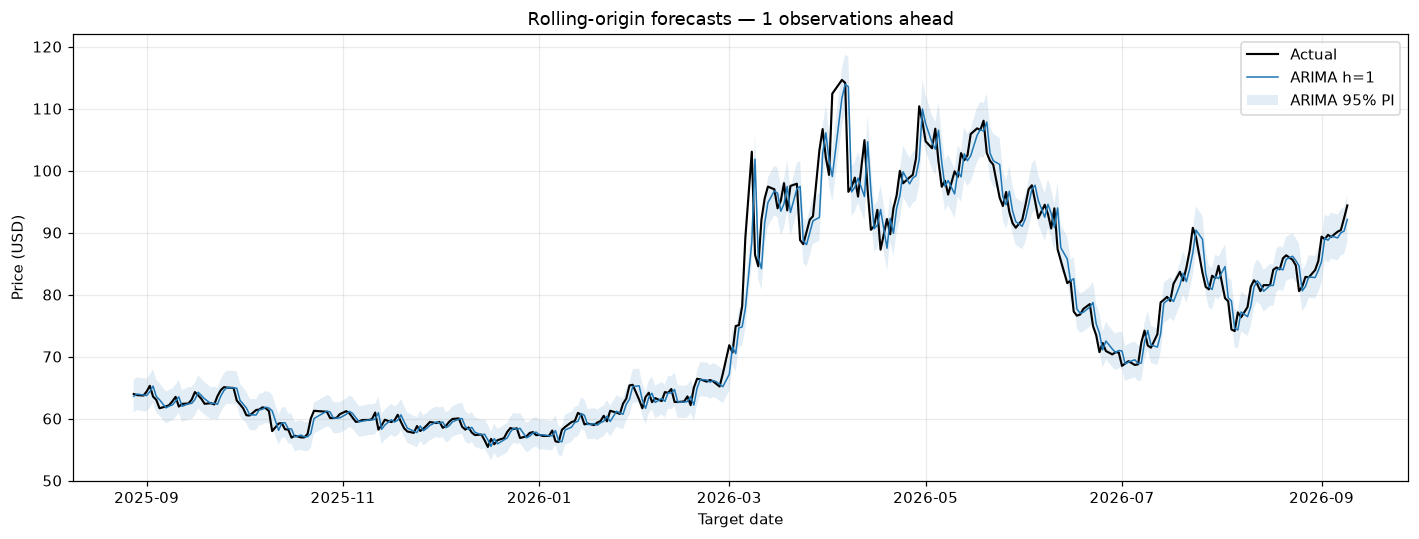

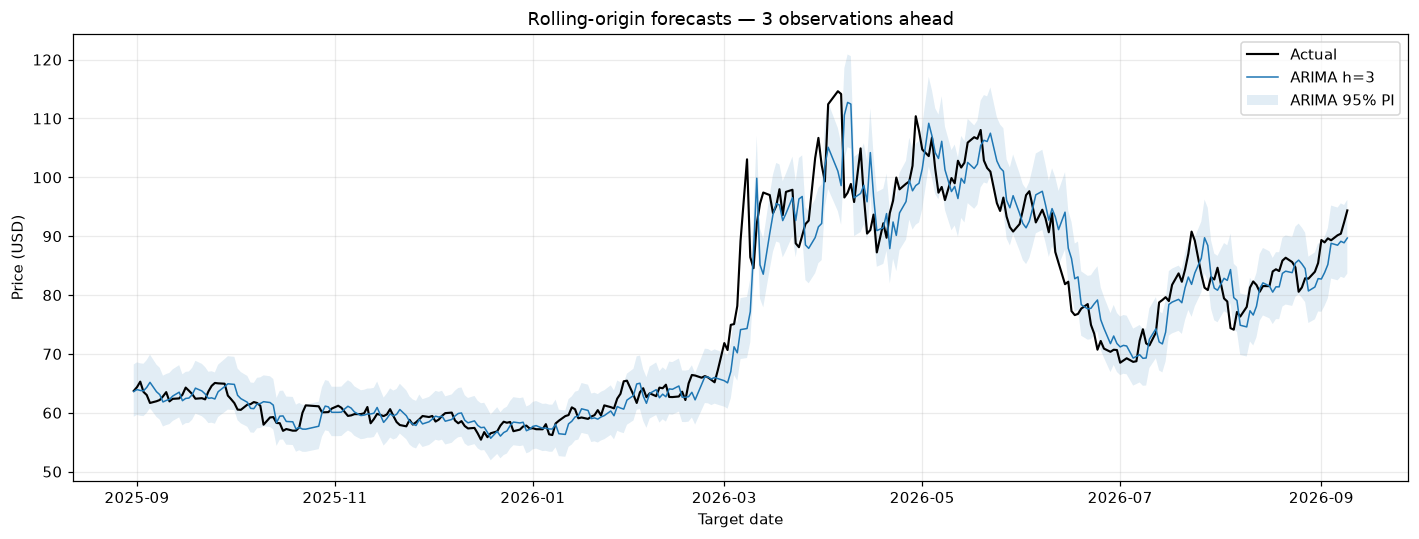

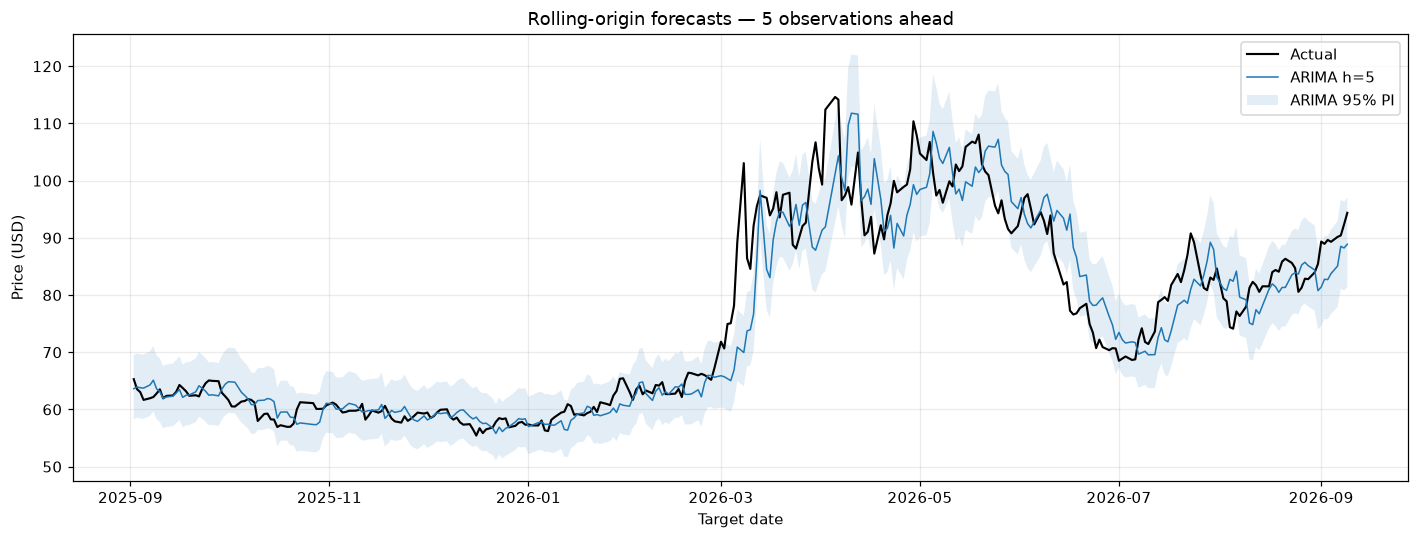

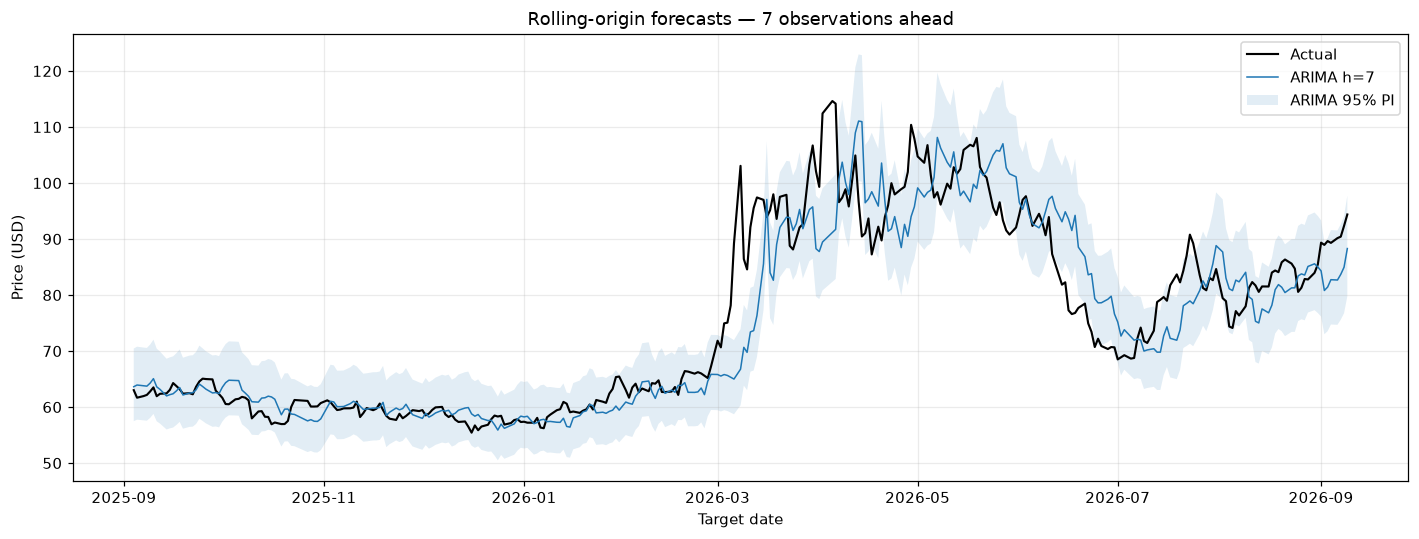

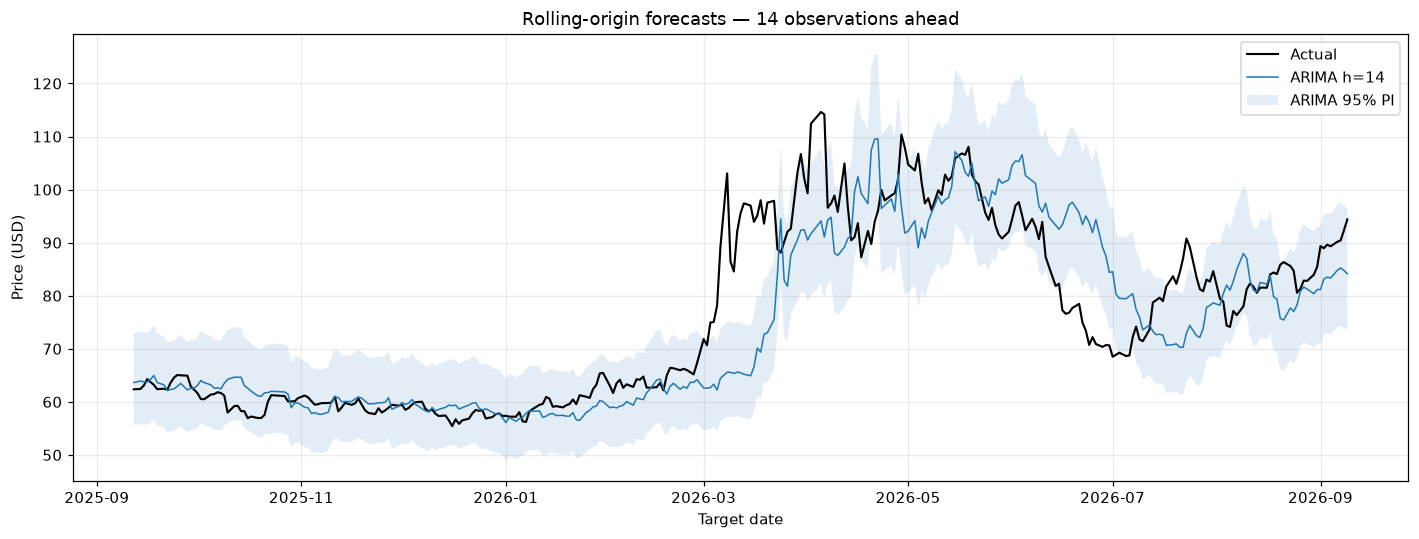

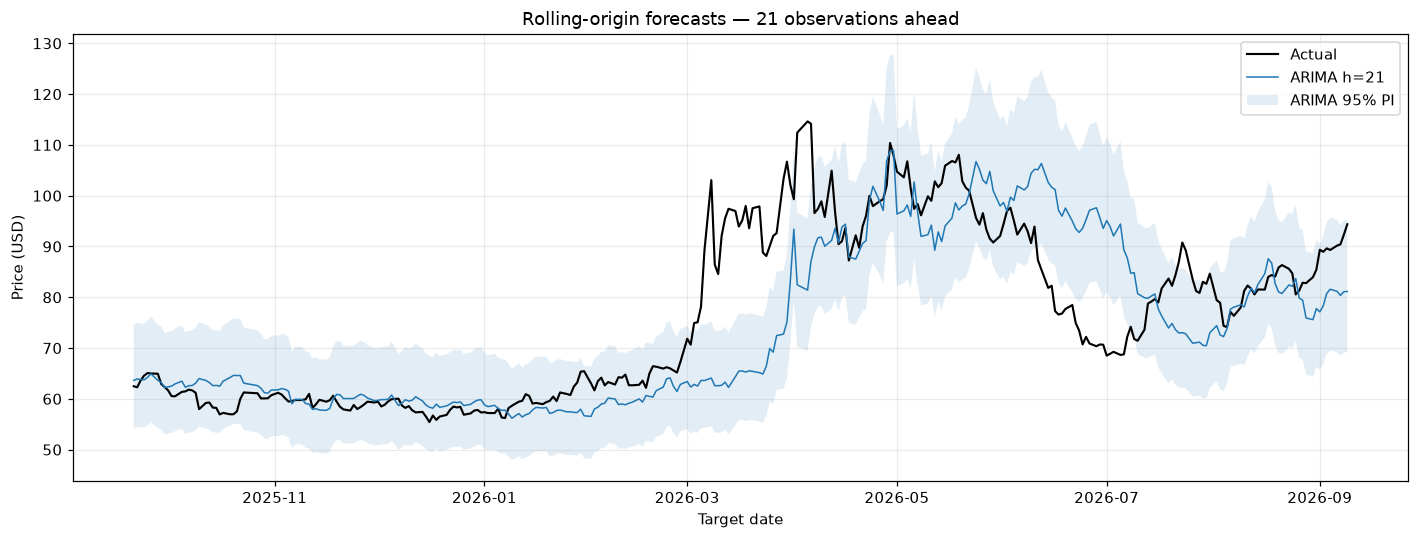

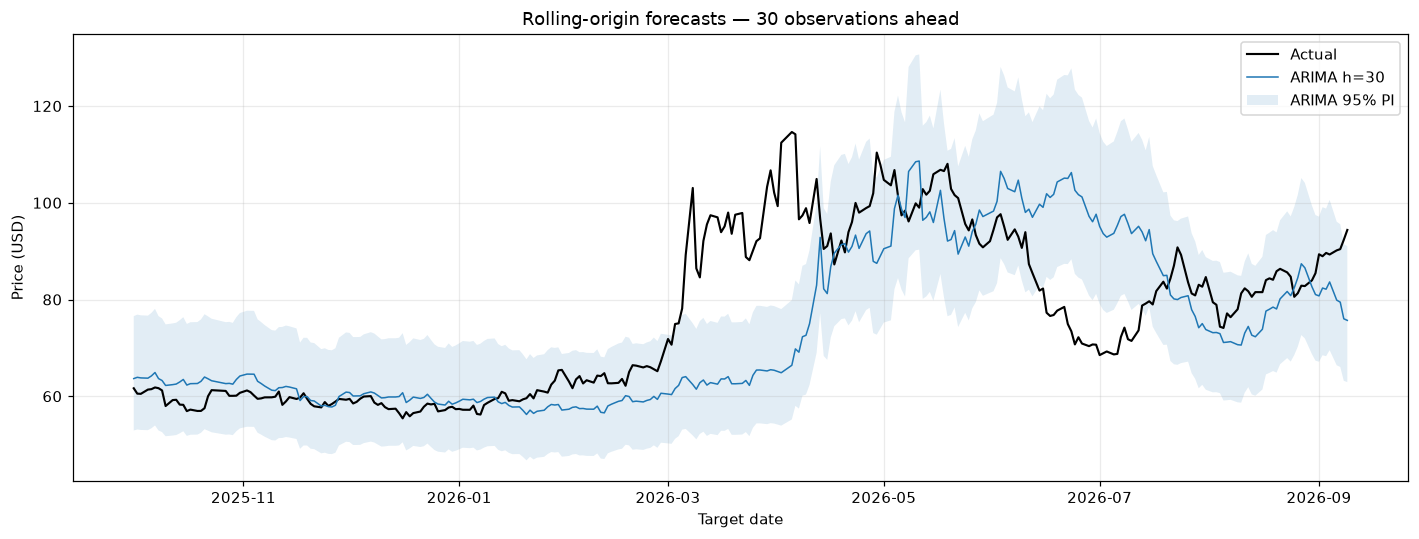

In [14]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    for h, group in forecasts.groupby('h', sort=True):
        fig, ax = plt.subplots(figsize=(13, 5))
        ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.4)
        ax.plot(group['target_date'], group['arima_fc'], label=f'ARIMA h={h}', linewidth=1)
        ax.fill_between(group['target_date'], group['arima_lo95'], group['arima_hi95'], alpha=0.13, label='ARIMA 95% PI')
        ax.set(title=f'Rolling-origin forecasts — {h} observations ahead', xlabel='Target date', ylabel='Price (USD)')
        ax.legend()
        save_figure(fig, f'09_forecast_h{h}.png')
    


### 8.3 Static 30-observation forecast from the final train origin

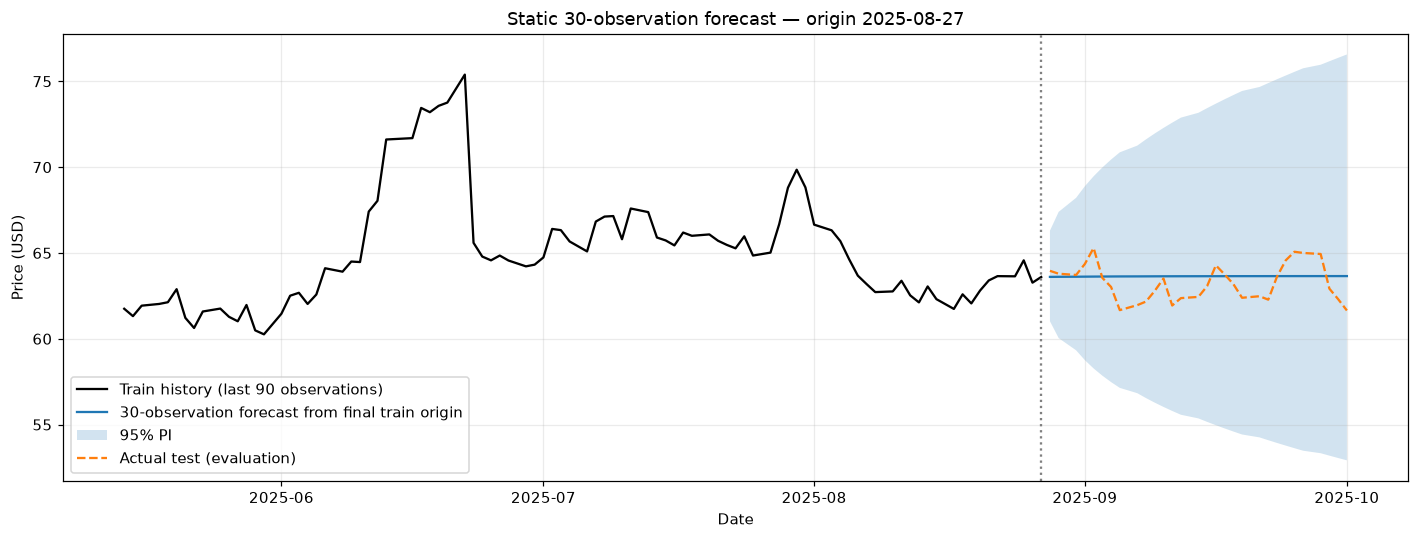

In [15]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    static_fc = res.get_forecast(steps=30)
    static_dates = test_price.index[:30]
    static_mean = np.exp(np.asarray(static_fc.predicted_mean))
    static_ci = np.exp(np.asarray(static_fc.conf_int(alpha=ALPHA)))
    save_table(pd.DataFrame(dict(target_date=static_dates, diagnostic_status=diagnostic_status, arima_fc=static_mean,
        arima_lo95=static_ci[:, 0], arima_hi95=static_ci[:, 1])), 'static_30d_forecast.csv')
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(train_price.iloc[-90:], color='black', label='Train history (last 90 observations)')
    ax.plot(static_dates, static_mean, label='30-observation forecast from final train origin')
    ax.fill_between(static_dates, static_ci[:, 0], static_ci[:, 1], alpha=0.2, label='95% PI')
    ax.plot(test_price.iloc[:30], linestyle='--', color='tab:orange', label='Actual test (evaluation)')
    ax.axvline(train_price.index[-1], color='gray', linestyle=':')
    ax.set(title=f'Static 30-observation forecast — origin {train_price.index[-1].date()}', ylabel='Price (USD)', xlabel='Date')
    ax.legend()
    save_figure(fig, '10_static_30d_fan.png')
    


### 8.4 RMSE and MAPE versus horizon

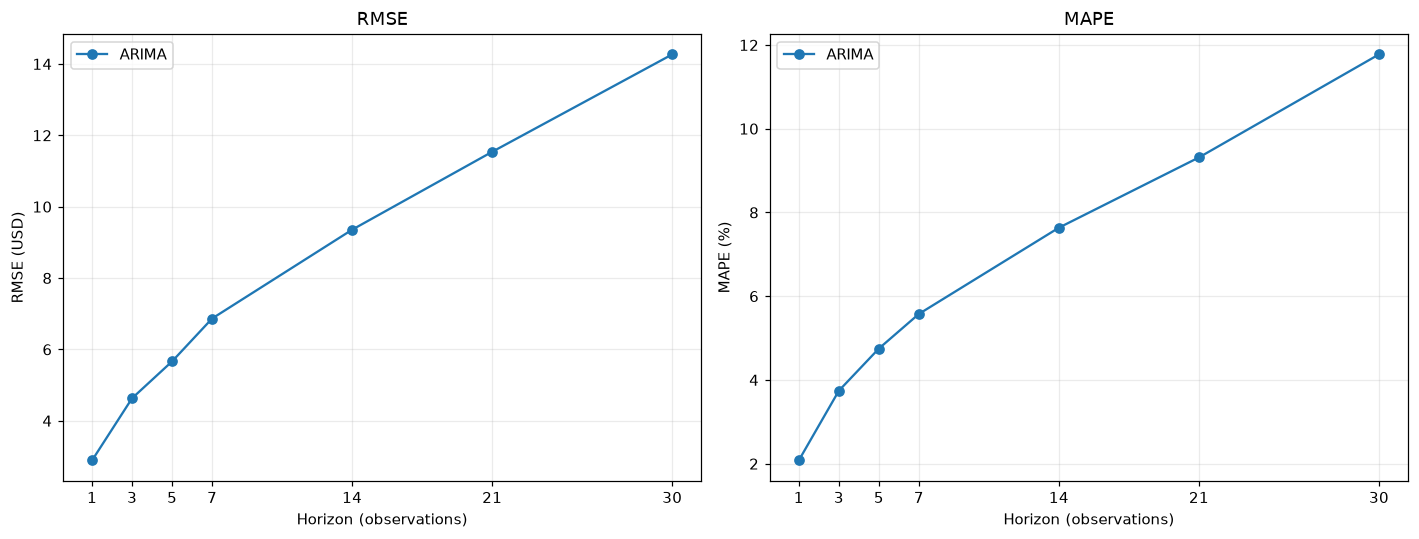

In [16]:
if not accepted_model:
    display(Markdown('**Skipped:** Step 6 accepted no model. No forecast or metric is generated by this cell.'))
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, metric, unit in zip(axes, ['RMSE', 'MAPE'], ['USD', '%']):
        ax.plot(evaluation['h'], evaluation[metric], marker='o', label='ARIMA')
        ax.set(title=metric, xlabel='Horizon (observations)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
        ax.legend()
    save_figure(fig, '11_error_vs_horizon.png')


## Step 9 - Summary and Interpretation
Summarize the selected model, train-only diagnostic evidence, test RMSE and MAPE by horizon, and the future forecast values.
Test metrics measure historical holdout performance. Future forecast rows have no observed target prices yet and are not included in those metrics.


In [17]:
# Summarize this execution, including the legitimate no-model outcome.
assert np.isfinite(df.Price).all() and df.Price.gt(0).all()
assert n_train == int(.8*n) and n_train+n_test == n
required_train_tables = ['library_versions.csv','data_quality.csv','split_summary.csv','stationarity_tests.csv',
    'grid_search_aic_bic.csv','top3_candidates.csv','auto_arima_cross_check.csv',
    'assumption_checks.csv','parameter_significance.csv','model_roots.csv','candidate_diagnostics.csv']
assert all(name in notebook_tables for name in required_train_tables)
lines = ['# WTI ARIMA - current execution', '',
    'Implementation reference: BTC_TEST/ARIMA_BTC.ipynb; Step 1-9 layout retained, with a user-authorized WTI residual-warning fallback in Step 6.',
    f'Data: {n} observed prices; Train/Test: {n_train}/{n_test}. Train ends {train_log.index[-1].date()}.',
    f'Units: {UNIT}. {CALENDAR_NOTE}',
    'No validation, no Test-guided selection, no full-data refit.',
    '', '## Selection status',
    (f'Forecast model: {final_label}; mode={selection_mode}; status={diagnostic_status}' if accepted_model else 'NO VALID MODEL: no Top 3 fit has valid roots.'),
    ('Train Ljung-Box and roots passed.' if train_diagnostics_passed else 'Train Ljung-Box did NOT pass. Forecasts are produced under the authorized root-valid AIC fallback, with remaining autocorrelation disclosed.'),
    '', '## Train stationarity', stationarity_tests.to_string(index=False),
    '', '## Top 3 diagnostics', candidate_diagnostics.to_string(index=False),
    '', '## Source audit',
    f'Rows with missing auxiliary volume: {df.Volume.isna().sum()}; source OHLC flags: {ohlc_flag.sum()}. Target Price is retained unchanged.',
    'Only log Price is modeled. OHLC flags are disclosed source issues, not a demonstrated cause of residual autocorrelation.',
    'A lower AIC does not guarantee white-noise residuals. Passing a diagnostic is not proof of forecast accuracy.',
    'The Ljung-Box threshold was not changed; FAIL remains FAIL. This WTI fallback differs from the BTC strict stopping rule.']
if accepted_model:
    required_forecast_tables = ['forecasts_long.csv','evaluation_by_horizon.csv','future_forecast_by_horizon.csv','static_30d_forecast.csv',
        *[f'forecasts_h{h}.csv' for h in HORIZONS], *[f'future_forecast_daily_{steps}d.csv' for steps in DAILY_FORECAST_WINDOWS]]
    assert all(name in notebook_tables for name in required_forecast_tables)
    assert np.array_equal(np.asarray(res.params), frozen_params)
    assert counts.to_dict() == {h:n_test-h+1 for h in HORIZONS}
    lines += ['', '## Test RMSE/MAPE', evaluation.to_string(index=False),
        '', '## Future forecasts', future_forecasts.to_string(index=False),
        'Point forecasts are exponentiated log-scale medians; intervals are model-based. ARCH/non-normality can impair coverage.']
else:
    lines += ['', '## Why no forecast appears',
        'No converged Top 3 candidate has valid roots, so even the residual-warning fallback cannot enable forecasts.',
        'Steps 7-8 were deliberately skipped. No Test/future forecasts, RMSE or MAPE were calculated in this execution.',
        '**Any old forecast/model files in OUTPUT/ARIMA_WTI are from earlier runs and are not current results.**']
lines += ['', '## Limits',
    'The source has Sunday observations and missing dates. Bitcoin daily-calendar assumptions were not imposed on WTI; no missing prices were filled.',
    'Instrument, contract, roll treatment, physical units and session timezone are not supplied. Future dates are projections, not verified exchange sessions.',
    'This user-requested redesign follows prior Test inspection; the existing Test period is not a new untouched holdout.',
    'Robust covariance is reporting-only and does not fix volatility dynamics or forecast interval calibration.',
    'Univariate prices do not observe news, policy, interest rates, inflation or unexpected events.']
summary_markdown = '\n\n'.join(lines)
display(Markdown(summary_markdown))
(SUMMARY_DIR/'execution_summary.md').write_text(summary_markdown, encoding='utf-8')
(SUMMARY_DIR/'summary.md').write_text(summary_markdown, encoding='utf-8')
display(Markdown('### Current-run diagnostic tables'))
for name in ['top3_candidates.csv','candidate_diagnostics.csv','assumption_checks.csv','source_ohlc_flags.csv']:
    display(Markdown(f'**{name}**'))
    show_table(notebook_tables[name])
audit = dict(completed=accepted_model, notebook_execution_completed=True,
    status=('COMPLETED' if train_diagnostics_passed else 'COMPLETED_WITH_RESIDUAL_WARNING') if accepted_model else 'NO_VALID_MODEL', asset=ASSET,
    selection_mode=selection_mode, train_diagnostics_passed=train_diagnostics_passed, diagnostic_status=diagnostic_status,
    model_accepted=accepted_model, selected_model=final_label, forecasts_generated=accepted_model,
    steps_executed=list(range(1,10)), forecast_steps_skipped=[] if accepted_model else [7,8],
    n=n, n_train=n_train, n_test=n_test, horizons=HORIZONS,
    selection=configuration['selection'], reference_sha256=configuration['reference_sha256'],
    source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    candidate_diagnostics=candidate_diagnostics.to_dict('records'),
    python_executable=sys.executable, table_count=len(notebook_tables), figure_count=len(notebook_figures),
    prior_exports_current=accepted_model)
if accepted_model:
    audit.update(parameters_frozen=np.array_equal(np.asarray(res.params), frozen_params),
        counts={int(h):int(c) for h,c in forecasts.groupby('h').size().items()})
write_json(SUMMARY_DIR/'execution_audit.json', audit)
print('Run All completed. Forecasts generated:', accepted_model, '; diagnostic status:', diagnostic_status)


# WTI ARIMA - current execution



Implementation reference: BTC_TEST/ARIMA_BTC.ipynb; Step 1-9 layout retained, with a user-authorized WTI residual-warning fallback in Step 6.

Data: 1601 observed prices; Train/Test: 1280/321. Train ends 2025-08-27.

Units: USD (source price). Horizons count successive observed records. Future dates use the source weekday pattern, not confirmed exchange sessions; source holidays/omissions and instrument details are unknown.

No validation, no Test-guided selection, no full-data refit.



## Selection status

Forecast model: ARIMA(1,1,1), trend=n; mode=ROOT_VALID_AIC_FALLBACK; status=RESIDUAL_AUTOCORRELATION_WARNING

Train Ljung-Box did NOT pass. Forecasts are produced under the authorized root-valid AIC fallback, with remaining autocorrelation disclosed.



## Train stationarity

        series test  statistic      p_value                                                                   critical_values                         conclusion  stationary                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       warnings
     log_price  ADF  -1.952253 3.078925e-01 {"1%": -3.4355013723543166, "5%": -2.863814884719495, "10%": -2.5679811700733755} non-stationary (fail to reject H0)       False                                                                                                                                                                                          adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
     log_price KPSS   2.176994 1.000000e-02                           {"10%": 0.347, "5%": 0.463, "2.5%": 0.574, "1%": 0.739}                     non-stationary       False The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned. | kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
diff_log_price  ADF -14.153659 2.140171e-26   {"1%": -3.435509501237317, "5%": -2.86381847140403, "10%": -2.5679830801661603}                         stationary        True                                                                                                                                                                                          adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
diff_log_price KPSS   0.058097 1.000000e-01                           {"10%": 0.347, "5%": 0.463, "2.5%": 0.574, "1%": 0.739}     stationary (fail to reject H0)        True The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned. | kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.



## Top 3 diagnostics

                model          AIC          BIC  ljung_box_pass  roots_pass  arch_pvalue  lb_pvalue_10  lb_pvalue_20  lb_pvalue_30  selected          selection_mode
ARIMA(1,1,1), trend=n -6227.463006 -6212.001505           False        True 1.485373e-16      0.033695      0.037757      0.036465      True ROOT_VALID_AIC_FALLBACK
ARIMA(2,1,1), trend=n -6226.490019 -6205.874684           False        True 1.368043e-16      0.028500      0.041440      0.040391     False ROOT_VALID_AIC_FALLBACK
ARIMA(0,1,0), trend=n -6226.091856 -6220.938022           False        True 3.883965e-16      0.013760      0.027846      0.026110     False ROOT_VALID_AIC_FALLBACK



## Source audit

Rows with missing auxiliary volume: 1601; source OHLC flags: 1. Target Price is retained unchanged.

Only log Price is modeled. OHLC flags are disclosed source issues, not a demonstrated cause of residual autocorrelation.

A lower AIC does not guarantee white-noise residuals. Passing a diagnostic is not proof of forecast accuracy.

The Ljung-Box threshold was not changed; FAIL remains FAIL. This WTI fallback differs from the BTC strict stopping rule.



## Test RMSE/MAPE

 h  n_points      RMSE      MAPE                diagnostic_status
 1       321  2.890739  2.079627 RESIDUAL_AUTOCORRELATION_WARNING
 3       319  4.631575  3.741735 RESIDUAL_AUTOCORRELATION_WARNING
 5       317  5.664465  4.748963 RESIDUAL_AUTOCORRELATION_WARNING
 7       315  6.865702  5.575784 RESIDUAL_AUTOCORRELATION_WARNING
14       308  9.355089  7.635627 RESIDUAL_AUTOCORRELATION_WARNING
21       301 11.537908  9.313710 RESIDUAL_AUTOCORRELATION_WARNING
30       292 14.267925 11.774598 RESIDUAL_AUTOCORRELATION_WARNING



## Future forecasts

origin_date  h target_date                                  target_date_status  arima_fc  arima_lo95  arima_hi95                diagnostic_status
 2026-09-09  1  2026-09-10 PROJECTED: source weekday pattern; sessions unknown 94.116301   90.294515   98.099848 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09  3  2026-09-13 PROJECTED: source weekday pattern; sessions unknown 93.674031   87.360323  100.444043 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09  5  2026-09-15 PROJECTED: source weekday pattern; sessions unknown 93.324795   85.475649  101.894721 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09  7  2026-09-17 PROJECTED: source weekday pattern; sessions unknown 93.048781   84.052541  103.007898 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09 14  2026-09-25 PROJECTED: source weekday pattern; sessions unknown 92.463690   80.740591  105.888919 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09 21  2026-10-04 PROJECTED: source weekday pattern; sessions unknown 92.205061   78.597254  108.168835 RESIDUAL_AUTOCORRELATION_WARNING
 2026-09-09 30  2026-10-14 PROJECTED: source weekday pattern; sessions unknown 92.071513   76.545531  110.746681 RESIDUAL_AUTOCORRELATION_WARNING

Point forecasts are exponentiated log-scale medians; intervals are model-based. ARCH/non-normality can impair coverage.



## Limits

The source has Sunday observations and missing dates. Bitcoin daily-calendar assumptions were not imposed on WTI; no missing prices were filled.

Instrument, contract, roll treatment, physical units and session timezone are not supplied. Future dates are projections, not verified exchange sessions.

This user-requested redesign follows prior Test inspection; the existing Test period is not a new untouched holdout.

Robust covariance is reporting-only and does not fix volatility dynamics or forecast interval calibration.

Univariate prices do not observe news, policy, interest rates, inflation or unexpected events.

### Current-run diagnostic tables

**top3_candidates.csv**

model,p,d,q,trend,AIC,BIC,converged,warnings,error
"ARIMA(1,1,1), trend=n",1,1,1,n,-6227.463006,-6212.001505,True,,
"ARIMA(2,1,1), trend=n",2,1,1,n,-6226.490019,-6205.874684,True,,
"ARIMA(0,1,0), trend=n",0,1,0,n,-6226.091856,-6220.938022,True,,


**candidate_diagnostics.csv**

...

**assumption_checks.csv**

model,test,statistic,p_value,pass_fail,note
"ARIMA(1,1,1), trend=n",Ljung-Box lag 10,16.673420,0.033695,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Ljung-Box lag 20,29.968163,0.037757,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Ljung-Box lag 30,42.790134,0.036465,FAIL,model_df=2
"ARIMA(1,1,1), trend=n",Mean = 0 (t-test),-0.302149,0.762588,PASS,Residual mean=-0.00017881
"ARIMA(1,1,1), trend=n",ARCH LM (10 lags),97.822172,0.000000,FAIL,
"ARIMA(1,1,1), trend=n",Jarque-Bera,1178.301223,0.000000,FAIL,"skew=-0.5627, kurtosis=7.5655"
"ARIMA(1,1,1), trend=n",AR roots outside unit circle,1.122967,NaN,PASS,All |root|>1: True
"ARIMA(1,1,1), trend=n",MA roots outside unit circle,1.086956,NaN,PASS,All |root|>1: True
"ARIMA(1,1,1), trend=n",Parameter significance: ar.L1,0.890498,0.000000,PASS,"Report only; estimate in statistic column, significance uses p < alpha"
"ARIMA(1,1,1), trend=n",Parameter significance: ma.L1,-0.920001,0.000000,PASS,"Report only; estimate in statistic column, significance uses p < alpha"


**source_ohlc_flags.csv**

Date,Price,Open,High,Low,Vol.,Change %,Day_of_Week,Volume
2026-03-27,92.650000,101.760000,92.210000,91.770000,NaN,0.006300,Friday,NaN


Run All completed. Forecasts generated: True ; diagnostic status: RESIDUAL_AUTOCORRELATION_WARNING


### Current execution status

The Step 9 summary above distinguishes forecast availability from statistical adequacy. WTI can generate forecasts with an explicit residual-autocorrelation warning under the user-authorized AIC/root-valid fallback. This does not turn a failed Ljung-Box check into a pass.


### Method references
- [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)
- [ARIMAResults.apply — fixed parameters](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.apply.html)
- [pmdarima auto_arima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html)
